# Parcial 1: Teoría de Aprendizaje de Máquina — 2026-2

**Profesor:** Diego Armando Pérez Rosero  
**Tema:** Métodos kernel, espacios de características y formulación matricial  

**Periodo:** 2026-2

**Convenciones de notación (consistentes en todo el documento).**

| Símbolo | Significado | Dimensión |
|---|---|---|
| $X$ | matriz de datos, fila $n$-ésima $x_n^\top$ | $N\times P$ |
| $\phi(\cdot)$, $\Phi$ | mapeo de características y matriz de diseño (fila $n$: $\phi(x_n)^\top$) | $\Phi\in\mathbb{R}^{N\times Q}$ |
| $t$, $w$ | vector de respuestas y vector de pesos | $\mathbb{R}^{N}$, $\mathbb{R}^{Q}$ |
| $\mathbf{1}_N$ | vector columna de unos | $N\times 1$ |
| $H=I_N-\tfrac1N\mathbf{1}_N\mathbf{1}_N^\top$ | matriz de centrado | $N\times N$ |
| $K$ | matriz de Gram, $K_{ij}=k(x_i,x_j)=\langle\phi(x_i),\phi(x_j)\rangle$ | $N\times N$ |

**Hilo conductor.** La Pregunta 1 usa un espacio de características para *predecir* (mínimos cuadrados → ML → MAP). La Pregunta 2 usa el mismo kernel y el mismo RKHS para *describir y comparar distribuciones* (embedding de media y MMD). La Pregunta 3 usa productos internos y matrices de centrado para *medir dependencia*, primero en el espacio original (Pearson) y luego en el RKHS (alineamiento centrado de kernels).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.optimize import minimize

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 6)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

# Pregunta 1: Regresión en espacios de características — mínimos cuadrados, máxima verosimilitud y MAP

> **Enunciado.** Sea un conjunto de datos i.i.d. $\{(x_n,t_n)\}_{n=1}^N$, $x_n\in\mathbb{R}^P$, $t_n\in\mathbb{R}$, un mapeo explícito $\phi:\mathbb{R}^P\to\mathbb{R}^Q$ y el modelo
> $$t_n=\phi(x_n)^\top w+\eta_n,\qquad w\in\mathbb{R}^Q,$$
> con $\eta_n\overset{i.i.d.}{\sim}\mathcal{N}(0,\sigma_\eta^2)$ cuando corresponda. $\Phi\in\mathbb{R}^{N\times Q}$ tiene filas $\phi(x_n)^\top$ y $t\in\mathbb{R}^N$.

**Espacios involucrados.**

- **Espacio original:** $x_n\in\mathbb{R}^P$.
- **Espacio de características:** $\phi(x_n)\in\mathbb{R}^Q$ (aquí $Q$ es finito y explícito).
- **Formulación matricial:** $t=\Phi w+\eta$, con $\Phi\in\mathbb{R}^{N\times Q}$, $w\in\mathbb{R}^{Q\times1}$, $\eta\in\mathbb{R}^{N\times1}$.
- **Formulación kernel inducida:** $K=\Phi\Phi^\top\in\mathbb{R}^{N\times N}$ (se usará al final de 1.2 como puente hacia el kernel trick; en esta pregunta no hace falta evaluar $K$ porque $\phi$ es explícito).

## 1.1 Mínimos cuadrados

> **Enunciado.** Plantee la función objetivo y deduzca, paso a paso, el estimador por mínimos cuadrados, incluyendo las condiciones necesarias para la existencia y unicidad de la solución.

#### Función objetivo

Se busca el $w$ que minimice la suma de errores cuadráticos (el cuadrado evita que errores positivos y negativos se cancelen y penaliza más los errores grandes):

$$J(w)=\sum_{n=1}^{N}\big(t_n-\phi(x_n)^\top w\big)^2=\|t-\Phi w\|_2^2,\qquad \hat w_{LS}=\arg\min_{w\in\mathbb{R}^Q}J(w).$$

#### Desarrollo del objetivo

Como $\|v\|_2^2=v^\top v$:

$$J(w)=(t-\Phi w)^\top(t-\Phi w)=t^\top t-t^\top\Phi w-w^\top\Phi^\top t+w^\top\Phi^\top\Phi w .$$

Los dos términos cruzados son escalares y uno es la transpuesta del otro, luego son iguales: $t^\top\Phi w=w^\top\Phi^\top t$. Entonces

$$J(w)=t^\top t-2\,w^\top\Phi^\top t+w^\top\Phi^\top\Phi\,w .$$

**Dimensiones:** $t^\top t\in\mathbb{R}$; $\Phi^\top t\in\mathbb{R}^{Q\times1}$; $\Phi^\top\Phi\in\mathbb{R}^{Q\times Q}$; $w^\top\Phi^\top\Phi w\in\mathbb{R}$.

#### Condición de primer orden (gradiente)

Con $\nabla_w(a^\top w)=a$ y $\nabla_w(w^\top Aw)=(A+A^\top)w=2Aw$ para $A$ simétrica (aquí $A=\Phi^\top\Phi$):

$$\nabla_wJ(w)=-2\Phi^\top t+2\Phi^\top\Phi\,w=0\quad\Longleftrightarrow\quad \boxed{\Phi^\top\Phi\,w=\Phi^\top t}\qquad\text{(ecuaciones normales)}.$$

Equivalentemente, $\Phi^\top(t-\Phi w)=0$: el residuo es ortogonal a las columnas de $\Phi$, es decir, $\Phi\hat w$ es la **proyección ortogonal** de $t$ sobre $\mathrm{Col}(\Phi)\subseteq\mathbb{R}^N$.

#### Condición de segundo orden y convexidad

El Hessiano es $\nabla^2_wJ=2\Phi^\top\Phi$, y para todo $v\in\mathbb{R}^Q$: $v^\top\Phi^\top\Phi v=\|\Phi v\|_2^2\ge0$. Luego $\Phi^\top\Phi\succeq0$, $J$ es **convexa** y todo punto estacionario es un **mínimo global**.

#### Existencia

Las ecuaciones normales **siempre** tienen solución: $\mathrm{Ker}(\Phi^\top\Phi)=\mathrm{Ker}(\Phi)$ (si $\Phi^\top\Phi v=0$ entonces $0=v^\top\Phi^\top\Phi v=\|\Phi v\|^2$), de donde $\mathrm{Im}(\Phi^\top\Phi)=\mathrm{Ker}(\Phi)^\perp=\mathrm{Im}(\Phi^\top)\ni\Phi^\top t$. Por tanto el mínimo siempre existe (es la proyección de $t$ sobre $\mathrm{Col}(\Phi)$).

#### Unicidad

El minimizador es único $\iff$ $\nabla^2J=2\Phi^\top\Phi\succ0$ $\iff$ $\mathrm{Ker}(\Phi)=\{0\}$ $\iff$ $\mathrm{rank}(\Phi)=Q$ (columnas linealmente independientes). Esto exige $N\ge Q$ y que ninguna característica sea combinación lineal de las demás. En ese caso $\Phi^\top\Phi$ es invertible y

$$\boxed{\hat w_{LS}=(\Phi^\top\Phi)^{-1}\Phi^\top t\in\mathbb{R}^{Q}}$$

Si $\mathrm{rank}(\Phi)<Q$ (por ejemplo $N<Q$ o características redundantes) hay infinitas soluciones $\hat w+\mathrm{Ker}(\Phi)$ con el mismo error; la de menor norma es $\Phi^+t=V\Sigma^+U^\top t$ (pseudoinversa, usando $\Phi=U\Sigma V^\top$).

## 1.2 Mínimos cuadrados regularizados

> **Enunciado.** Formule el problema con penalización cuadrática $\lambda\|w\|_2^2$, con $\lambda>0$, y derive su solución cerrada. Explique el efecto del parámetro de regularización.

#### Formulación

$$J_\lambda(w)=\|t-\Phi w\|_2^2+\lambda\|w\|_2^2,\qquad \hat w_{\lambda}=\arg\min_{w}J_\lambda(w),\quad\lambda>0.$$

#### Derivación

$$J_\lambda(w)=t^\top t-2w^\top\Phi^\top t+w^\top\Phi^\top\Phi w+\lambda w^\top w=t^\top t-2w^\top\Phi^\top t+w^\top(\Phi^\top\Phi+\lambda I_Q)w .$$

$$\nabla_wJ_\lambda=-2\Phi^\top t+2(\Phi^\top\Phi+\lambda I_Q)w=0\;\Longrightarrow\;(\Phi^\top\Phi+\lambda I_Q)\,w=\Phi^\top t .$$

**Segundo orden.** $\nabla^2J_\lambda=2(\Phi^\top\Phi+\lambda I_Q)$. Si $\mu_i\ge0$ son los valores propios de $\Phi^\top\Phi$, los de la matriz regularizada son $\mu_i+\lambda\ge\lambda>0$. Por tanto es **definida positiva para cualquier $\Phi$** (incluso con $N<Q$ o columnas colineales), $J_\lambda$ es estrictamente convexa, la matriz es invertible y la solución es **única**:

$$\boxed{\hat w_\lambda=(\Phi^\top\Phi+\lambda I_Q)^{-1}\Phi^\top t\in\mathbb{R}^{Q}}$$

> **Nota de signo.** El término $+\lambda I_Q$ es el correcto: restar $\lambda I$ podría volver singular la matriz y no corresponde a minimizar $J_\lambda$ con $\lambda>0$.

#### Efecto de $\lambda$ (vía SVD)



- $\lambda\to0$: se recupera mínimos cuadrados (o la pseudoinversa si $\Phi$ no tiene rango completo). Menor sesgo, mayor varianza, riesgo de sobreajuste.
- $\lambda\to\infty$: $\hat w_\lambda\approx\Phi^\top t/\lambda\to0$. Mayor sesgo, menor varianza, subajuste.
- $\lambda$ intermedio: compromiso sesgo–varianza.

#### Puente hacia la formulación kernel (forma dual)

Como $(\Phi^\top\Phi+\lambda I_Q)\Phi^\top=\Phi^\top\Phi\Phi^\top+\lambda\Phi^\top=\Phi^\top(\Phi\Phi^\top+\lambda I_N)$, multiplicando por las inversas se obtiene

$$\hat w_\lambda=\Phi^\top\underbrace{(\Phi\Phi^\top+\lambda I_N)^{-1}t}_{\alpha\in\mathbb{R}^N}=\Phi^\top(K+\lambda I_N)^{-1}t,\qquad K=\Phi\Phi^\top\in\mathbb{R}^{N\times N}.$$

La forma primal invierte una matriz $Q\times Q$ y la dual una $N\times N$ que solo depende de productos internos $\langle\phi(x_i),\phi(x_j)\rangle$: es el *kernel trick* (se verifica numéricamente en 1.5).

## 1.3 Máxima verosimilitud

> **Enunciado.** Bajo el supuesto de ruido gaussiano i.i.d., construya la función de verosimilitud y su logaritmo, y obtenga el estimador de $w$ por máxima verosimilitud. Explicite su relación con mínimos cuadrados.

#### Modelo probabilístico

Como $t_n=\phi(x_n)^\top w+\eta_n$ con $\eta_n\sim\mathcal{N}(0,\sigma_\eta^2)$, y $w$, $x_n$ fijos, cada respuesta cumple $t_n\mid x_n,w\sim\mathcal{N}\big(\phi(x_n)^\top w,\sigma_\eta^2\big)$.

#### Verosimilitud

Por independencia de los $\eta_n$:

$$p(t\mid\Phi,w)=\prod_{n=1}^{N}\mathcal{N}\big(t_n\mid\phi(x_n)^\top w,\sigma_\eta^2\big)=\prod_{n=1}^{N}\frac{1}{\sqrt{2\pi\sigma_\eta^2}}\exp\!\Big(-\frac{(t_n-\phi(x_n)^\top w)^2}{2\sigma_\eta^2}\Big).$$

#### Log-verosimilitud

Como $\log$ es estrictamente creciente, maximizar la verosimilitud equivale a maximizar su logaritmo (propiedades $\log(ab)=\log a+\log b$, $\log\prod=\sum\log$):

$$\ell(w)=\log p(t\mid\Phi,w)=-\frac N2\log(2\pi\sigma_\eta^2)-\frac{1}{2\sigma_\eta^2}\sum_{n=1}^N\big(t_n-\phi(x_n)^\top w\big)^2=-\frac N2\log(2\pi\sigma_\eta^2)-\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|_2^2 .$$

#### Estimador

El primer término no depende de $w$, y $\frac{1}{2\sigma_\eta^2}>0$ es una constante. Por tanto

$$\hat w_{ML}=\arg\max_w\ell(w)=\arg\min_w\|t-\Phi w\|_2^2 .$$

Derivando: $\nabla_w\ell=\frac{1}{\sigma_\eta^2}\Phi^\top(t-\Phi w)=0\Rightarrow\Phi^\top\Phi w=\Phi^\top t$, las mismas ecuaciones normales de 1.1. Además $\nabla^2\ell=-\frac{1}{\sigma_\eta^2}\Phi^\top\Phi\preceq0$ ($\ell$ cóncava). Entonces

$$\boxed{\hat w_{ML}=(\Phi^\top\Phi)^{-1}\Phi^\top t=\hat w_{LS}}\qquad(\text{con }\mathrm{rank}\,\Phi=Q).$$

**Relación con mínimos cuadrados.** Bajo ruido gaussiano i.i.d. de varianza constante, **mínimos cuadrados = máxima verosimilitud**: el error cuadrático es (salvo constantes) la log-verosimilitud negativa gaussiana. El valor de $\sigma_\eta^2$ no altera $\hat w_{ML}$. Si además se estima la varianza, $\partial\ell/\partial\sigma_\eta^2=0$ da $\hat\sigma^2_{\eta,ML}=\frac1N\|t-\Phi\hat w\|_2^2$ (mismo procedimiento que el de la media y varianza de una gaussiana en clase; es sesgado porque divide entre $N$ y no entre $N-Q$).

## 1.4 Máximo a posteriori (MAP)

> **Enunciado.** Suponga además el prior $w\sim\mathcal{N}(0,\sigma_w^2I_Q)$. A partir de la regla de Bayes, deduzca el problema de optimización MAP y su solución; establezca la relación entre $\sigma_\eta^2$, $\sigma_w^2$ y la regularización cuadrática.

#### Regla de Bayes

$$p(w\mid t)=\frac{p(t\mid w)\,p(w)}{p(t)}\ \propto\ p(t\mid w)\,p(w),$$

pues $p(t)$ no depende de $w$. Con $p(t\mid w)$ de 1.3 y el prior

$$p(w)=\frac{1}{(2\pi\sigma_w^2)^{Q/2}}\exp\!\Big(-\frac{\|w\|_2^2}{2\sigma_w^2}\Big).$$

#### Problema MAP

$$\hat w_{MAP}=\arg\max_w\log p(w\mid t)=\arg\max_w\Big[-\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|_2^2-\frac{1}{2\sigma_w^2}\|w\|_2^2\Big]+\text{cte},$$

es decir (cambiando el signo y multiplicando por $2\sigma_\eta^2>0$, lo que no cambia el argumento óptimo):

$$\hat w_{MAP}=\arg\min_w\ \|t-\Phi w\|_2^2+\underbrace{\frac{\sigma_\eta^2}{\sigma_w^2}}_{\lambda}\|w\|_2^2 .$$

#### Relación con la regularización cuadrática

$$\boxed{\lambda=\frac{\sigma_\eta^2}{\sigma_w^2}\quad\Longleftrightarrow\quad\sigma_w^2=\frac{\sigma_\eta^2}{\lambda}}$$

Es exactamente el problema de 1.2, así que (derivación idéntica)

$$\boxed{\hat w_{MAP}=(\Phi^\top\Phi+\lambda I_Q)^{-1}\Phi^\top t,\qquad\lambda=\sigma_\eta^2/\sigma_w^2}$$

**Posterior completo.** Es gaussiano: su precisión es $\frac{1}{\sigma_\eta^2}\Phi^\top\Phi+\frac{1}{\sigma_w^2}I_Q=\frac{1}{\sigma_\eta^2}(\Phi^\top\Phi+\lambda I_Q)$, luego

$$w\mid t\sim\mathcal{N}\Big(\underbrace{(\Phi^\top\Phi+\lambda I_Q)^{-1}\Phi^\top t}_{\text{media}=\text{moda}=\hat w_{MAP}},\ \sigma_\eta^2(\Phi^\top\Phi+\lambda I_Q)^{-1}\Big).$$

**Interpretación.** Un prior estrecho ($\sigma_w^2$ pequeño, o ruido grande) $\Rightarrow\lambda$ grande $\Rightarrow$ pesos pequeños. Un prior difuso ($\sigma_w^2\to\infty$) $\Rightarrow\lambda\to0\Rightarrow\hat w_{MAP}\to\hat w_{ML}$. Ridge es MAP con prior gaussiano; mínimos cuadrados es ML (o MAP con prior plano).

## 1.5 Implementación y análisis

> **Enunciado.** Implemente y compare los cuatro enfoques en Python con $N=300$, $P=5$, $Q=20$, $\Phi:\mathbb{R}^{N\times P}\to\mathbb{R}^{N\times Q}$.

**Diseño del experimento.**

- $X\in\mathbb{R}^{300\times5}$ con entradas i.i.d. $\mathcal{N}(0,1)$ (semilla fija).
- **Orden de las $Q=20$ columnas de $\Phi(X)$:** (i) las 5 columnas originales $x_1,\dots,x_5$; (ii) los 5 cuadrados $x_1^2,\dots,x_5^2$; (iii) los $\binom52=10$ productos $x_ix_j$ con $i<j$ en orden lexicográfico: $(1,2),(1,3),(1,4),(1,5),(2,3),(2,4),(2,5),(3,4),(3,5),(4,5)$.
- $w^\ast\in\mathbb{R}^{20}$ con entradas $\mathcal{N}(0,1)$, $\eta_n\sim\mathcal{N}(0,0.5^2)$, $t=\Phi(X)w^\ast+\eta$.
- Partición aleatoria 80 % / 20 % (240 entrenamiento, 60 prueba). Todos los estimadores usan **solo entrenamiento**.
- LS y Ridge: forma cerrada. **ML y MAP: se maximizan numéricamente** (L-BFGS-B con gradiente analítico, partiendo de $w=0$) la log-verosimilitud y el log-posterior de 1.3 y 1.4; así la coincidencia con LS y Ridge es una verificación y no una tautología.
- $\lambda=1$ y $\sigma_w^2=\sigma_\eta^2/\lambda=0.25$.

### Guía de lectura — 1.5.1 Datos, mapeo y partición

En la siguiente celda se genera el experimento completo y se comprueban sus dimensiones:

1. **Entradas:** `X` tiene forma `(300, 5)`.
2. **Mapa de características:** `feature_map(X)` concatena 5 características lineales, 5 cuadrados y 10 productos por pares. Por eso `Phi` tiene forma `(300, 20)`.
3. **Respuesta sintética:** se generan los pesos verdaderos `w_star`, el ruido gaussiano `eta` y las respuestas `t = Phi @ w_star + eta`.
4. **Entrenamiento/prueba:** la partición es 80/20; los estimadores se ajustan únicamente con los 240 datos de entrenamiento.
5. **Existencia y unicidad:** se calcula el rango de `Phi_tr`, el condicionamiento de `Phi_tr.T @ Phi_tr` y su menor autovalor.

**Qué verificar en la salida:** `Phi: (300, 20)`, `train: (240, 20)`, `test: (60, 20)` y rango igual a `Q = 20`.

In [ ]:
from itertools import combinations

# ---------------- datos ----------------
SEED = 42
rng = np.random.default_rng(SEED)
N, P, Q = 300, 5, 20
sigma_eta = 0.5

X = rng.standard_normal((N, P))                        # N x P

def feature_map(X):
    """Phi(X) in R^{N x Q}: [x_1..x_P | x_1^2..x_P^2 | x_i x_j (i<j, orden lexicografico)]"""
    P = X.shape[1]
    lineales   = X                                                          # P columnas
    cuadrados  = X ** 2                                                     # P columnas
    pares_idx  = list(combinations(range(P), 2))                            # C(P,2) = 10 pares
    productos  = np.column_stack([X[:, i] * X[:, j] for i, j in pares_idx]) # 10 columnas
    return np.hstack([lineales, cuadrados, productos]), pares_idx

Phi, pares_idx = feature_map(X)
assert Phi.shape == (N, Q)
print("Orden de los productos (1-indexado):", [(i+1, j+1) for i, j in pares_idx])

w_star = rng.standard_normal(Q).reshape(Q, 1)                        # pesos verdaderos
eta    = sigma_eta * rng.standard_normal(N).reshape(N, 1)            # ruido
t      = Phi @ w_star + eta                             # N

# ---------------- particion 80/20 ----------------
perm = rng.permutation(N)
n_tr = int(0.8 * N)
idx_tr, idx_te = perm[:n_tr], perm[n_tr:]
Phi_tr, t_tr = Phi[idx_tr], t[idx_tr]
Phi_te, t_te = Phi[idx_te], t[idx_te]
print(f"Phi: {Phi.shape} | train: {Phi_tr.shape} | test: {Phi_te.shape}")

# Verificacion de dimensiones y correspondencia
assert Phi.shape == (N, Q)
assert t.shape == (N, 1)
assert Phi_tr.shape == (n_tr, Q)
assert t_tr.shape == (n_tr, 1)
assert Phi_te.shape[0] + Phi_tr.shape[0] == N
assert len(set(idx_tr) & set(idx_te)) == 0

# condiciones de 1.1 (existencia y unicidad)
G = Phi_tr.T @ Phi_tr
eig = np.linalg.eigvalsh(G)
print(f"rank(Phi_tr) = {np.linalg.matrix_rank(Phi_tr)} (= Q)  |  cond(Phi^T Phi) = {np.linalg.cond(G):.2f}  |  menor autovalor = {eig.min():.2f}")

Orden de los productos (1-indexado): [(1, 2), (1, 3), (1, 4), (1, 5), (2, 3), (2, 4), (2, 5), (3, 4), (3, 5), (4, 5)]
Phi: (300, 20) | train: (240, 20) | test: (60, 20)
rank(Phi_tr) = 20 (= Q)  |  cond(Phi^T Phi) = 16.54  |  menor autovalor = 109.49


### Guía de lectura — 1.5.2 Inspección de `w_star`

Esta celda es únicamente diagnóstica. Imprime el tipo, número de dimensiones, forma y contenido de `w_star` para que se vea
 entre un **vector columna** de forma `(20, 1)`

In [ ]:
def inspeccionar_vector(vec, nombre="vector"):
    print(f"--- Inspeccionando {nombre} ---")
    print(f"Tipo: {type(vec)}")
    print(f"Dimensión (ndim): {vec.ndim}")
    print(f"Forma (shape): {vec.shape}")
    print(f"Número total de elementos (size): {vec.size}")
    print(f"Contenido:\n{vec}")

try:
    # Ejecutamos la función para inspeccionar w_star
    inspeccionar_vector(w_star, "w_star")
except NameError as e:
    print(f"Error de ejecución: {e}")
    print("\n[!] NOTA: Ve a la celda anterior (NkQOeaoSQ_bf), corrige el error de 'phi.shape' a 'Phi.shape' (con P mayúscula), ejecútala y luego vuelve a correr esta celda.")

--- Inspeccionando w_star ---
Tipo: <class 'numpy.ndarray'>
Dimensión (ndim): 2
Forma (shape): (20, 1)
Número total de elementos (size): 20
Contenido:
[[-0.5663]
 [-0.6246]
 [ 1.3251]
 [ 0.3303]
 [-0.2117]
 [ 0.4987]
 [-2.1072]
 [-0.0431]
 [ 1.9975]
 [ 0.1323]
 [ 0.0679]
 [ 0.5481]
 [ 0.8956]
 [-1.9975]
 [-1.6823]
 [ 0.2103]
 [-0.7149]
 [ 1.312 ]
 [-0.3152]
 [-1.9345]]


### Guía de lectura — 1.5.3 Los cuatro estimadores y sus verificaciones

La siguiente celda compara:

- **Mínimos cuadrados (LS):** solución cerrada con `np.linalg.solve`.
- **Ridge:** solución cerrada con la penalización `+ lam * I`.
- **Máxima verosimilitud (ML):** minimización numérica de la log-verosimilitud negativa, con gradiente analítico.
- **Máximo a posteriori (MAP):** minimización numérica del log-posterior negativo; añade la contribución del prior gaussiano.

También calcula MSE en entrenamiento y prueba, la distancia entre los pesos estimados y los pesos verdaderos, la equivalencia primal/dual y los factores de encogimiento. Las versiones `.ravel()` convierten los vectores columna a forma plana para que coincidan con las operaciones del optimizador.

**Qué revisar:** LS debe coincidir numéricamente con ML, Ridge con MAP, y las soluciones primal y dual deben diferir solo por redondeo numérico.

In [ ]:
lam = 1.0
sigma_w2 = sigma_eta**2 / lam           # prior compatible con la convencion ||t-Phi w||^2 + lam ||w||^2

# Aplanamos t_tr y t_te para evitar problemas de broadcasting en la optimización y operaciones duales
t_tr_flat = t_tr.ravel()
t_te_flat = t_te.ravel()

# ---------- 1) Minimos cuadrados (forma cerrada) ----------
w_ls = np.linalg.solve(Phi_tr.T @ Phi_tr, Phi_tr.T @ t_tr_flat)

# ---------- 2) Minimos cuadrados regularizados (forma cerrada) ----------
w_rg = np.linalg.solve(Phi_tr.T @ Phi_tr + lam * np.eye(Q), Phi_tr.T @ t_tr_flat)

# ---------- 3) Maxima verosimilitud: se maximiza numericamente la log-verosimilitud ----------
def negloglik(w):
    r = t_tr_flat - Phi_tr @ w
    val  = 0.5 * len(t_tr_flat) * np.log(2*np.pi*sigma_eta**2) + 0.5 * np.sum(r**2) / sigma_eta**2
    grad = -(Phi_tr.T @ r) / sigma_eta**2
    return val, grad

opt = dict(maxiter=10000, ftol=1e-16, gtol=1e-12)
res_ml = minimize(negloglik, np.zeros(Q), jac=True, method="L-BFGS-B", options=opt)
w_ml = res_ml.x

# ---------- 4) MAP: se maximiza numericamente el log-posterior ----------
def neglogpost(w):
    r = t_tr_flat - Phi_tr @ w
    val  = 0.5 * np.sum(r**2) / sigma_eta**2 + 0.5 * np.sum(w**2) / sigma_w2
    grad = -(Phi_tr.T @ r) / sigma_eta**2 + w / sigma_w2
    return val, grad

res_map = minimize(neglogpost, np.zeros(Q), jac=True, method="L-BFGS-B", options=opt)
w_map = res_map.x

# ---------- metricas ----------
mse = lambda w, A, b: np.mean((b - A @ w) ** 2)
estimadores = {"Minimos cuadrados": w_ls, "Ridge (lambda=1)": w_rg, "Max. verosimilitud": w_ml, "MAP (sigma_w^2=0.25)": w_map}
tabla = pd.DataFrame(
    [(n, mse(w, Phi_tr, t_tr_flat), mse(w, Phi_te, t_te_flat), np.linalg.norm(w - w_star_flat)) for n, w in estimadores.items()],
    columns=["Estimador", "MSE entrenamiento", "MSE prueba", "||w_hat - w*||_2"]).set_index("Estimador")
print(tabla)

print("\n--- Coincidencias esperadas ---")
print(f"||w_LS  - w_ML ||_2 = {np.linalg.norm(w_ls - w_ml):.2e}   (LS = ML)")
print(f"||w_Rdg - w_MAP||_2 = {np.linalg.norm(w_rg - w_map):.2e}   (Ridge = MAP, lambda = sigma_eta^2/sigma_w^2 = {sigma_eta**2/sigma_w2:.1f})")
print(f"||w_LS  - w_Rdg||_2 = {np.linalg.norm(w_ls - w_rg):.2e}   (distintos: efecto de lambda)")

# forma dual (kernel trick, ver 1.2): w = Phi^T (Phi Phi^T + lam I_N)^-1 t
K_tr = Phi_tr @ Phi_tr.T
w_dual = Phi_tr.T @ np.linalg.solve(K_tr + lam * np.eye(len(t_tr_flat)), t_tr_flat)
print(f"||w_primal - w_dual||_2 = {np.linalg.norm(w_rg - w_dual):.2e}   (K = Phi Phi^T in R^{K_tr.shape})")

# ruido estimado por ML y referencia teorica
print(f"\nsigma_eta^2 verdadero = {sigma_eta**2:.4f} | sigma^2_ML = {np.mean((t_tr_flat - Phi_tr @ w_ls)**2):.4f}")
print("factores de encogimiento sigma_i^2/(sigma_i^2+lam): min = %.4f, max = %.4f" % ((eig/(eig+lam)).min(), (eig/(eig+lam)).max()))

                      MSE entrenamiento  MSE prueba  ||w_hat - w*||_2
Estimador                                                            
Minimos cuadrados              0.238900    0.285008          0.120489
Ridge (lambda=1)               0.239233    0.279331          0.125542
Max. verosimilitud             0.238900    0.285008          0.120489
MAP (sigma_w^2=0.25)           0.239233    0.279331          0.125542

--- Coincidencias esperadas ---
||w_LS  - w_ML ||_2 = 2.61e-09   (LS = ML)
||w_Rdg - w_MAP||_2 = 7.33e-10   (Ridge = MAP, lambda = sigma_eta^2/sigma_w^2 = 1.0)
||w_LS  - w_Rdg||_2 = 1.89e-02   (distintos: efecto de lambda)
||w_primal - w_dual||_2 = 1.47e-14   (K = Phi Phi^T in R^(240, 240))

sigma_eta^2 verdadero = 0.2500 | sigma^2_ML = 0.2389
factores de encogimiento sigma_i^2/(sigma_i^2+lam): min = 0.9909, max = 0.9994


### Guía de lectura — 1.5.4 Comparación estadística con 300 repeticiones

Una sola partición puede hacer que LS o Ridge parezcan mejores por azar. La siguiente celda repite el experimento con **300 semillas independientes** y compara LS (`lambda = 0`), Ridge (`lambda = 0.25`) y Ridge (`lambda = 1`).

La tabla informa las medias, errores estándar y porcentaje de repeticiones en que cada Ridge mejora frente a LS. Las cuatro figuras muestran el MSE de prueba, el error en los pesos, la distribución del MSE y la frecuencia de mejora.

**Interpretación:** el resultado es específico de este diseño (`N_train = 240`, `Q = 20` y el nivel de ruido fijado); no se debe concluir que Ridge siempre mejora o siempre empeora a LS.


RESULTADOS PROMEDIO DE LOS 300 EXPERIMENTOS


,Estimador,Lambda,MSE prueba (media),EE del MSE,Error pesos^2 (media),EE error pesos^2,||w_hat||^2 (media),Mejora MSE vs LS (%),Mejora pesos vs LS (%)
0,LS,0.00,0.27616,0.00293,0.02199,0.00043,19.85682,—,—
1,Ridge,0.25,0.27616,0.00293,0.02193,0.00043,19.81513,53.3%,55.7%
2,Ridge,1.00,0.27652,0.00293,0.02208,0.00043,19.69107,46.7%,47.0%



Número de repeticiones: 300
Varianza teórica del ruido: sigma_eta^2 = 0.25000

Ridge (lambda=1) mejora a LS en MSE de prueba en 46.7% de las repeticiones.
Ridge (lambda=1) mejora a LS en error de pesos en 47.0% de las repeticiones.


/tmp/ipykernel_1501/1719225006.py:284: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  cajas = ax.boxplot(


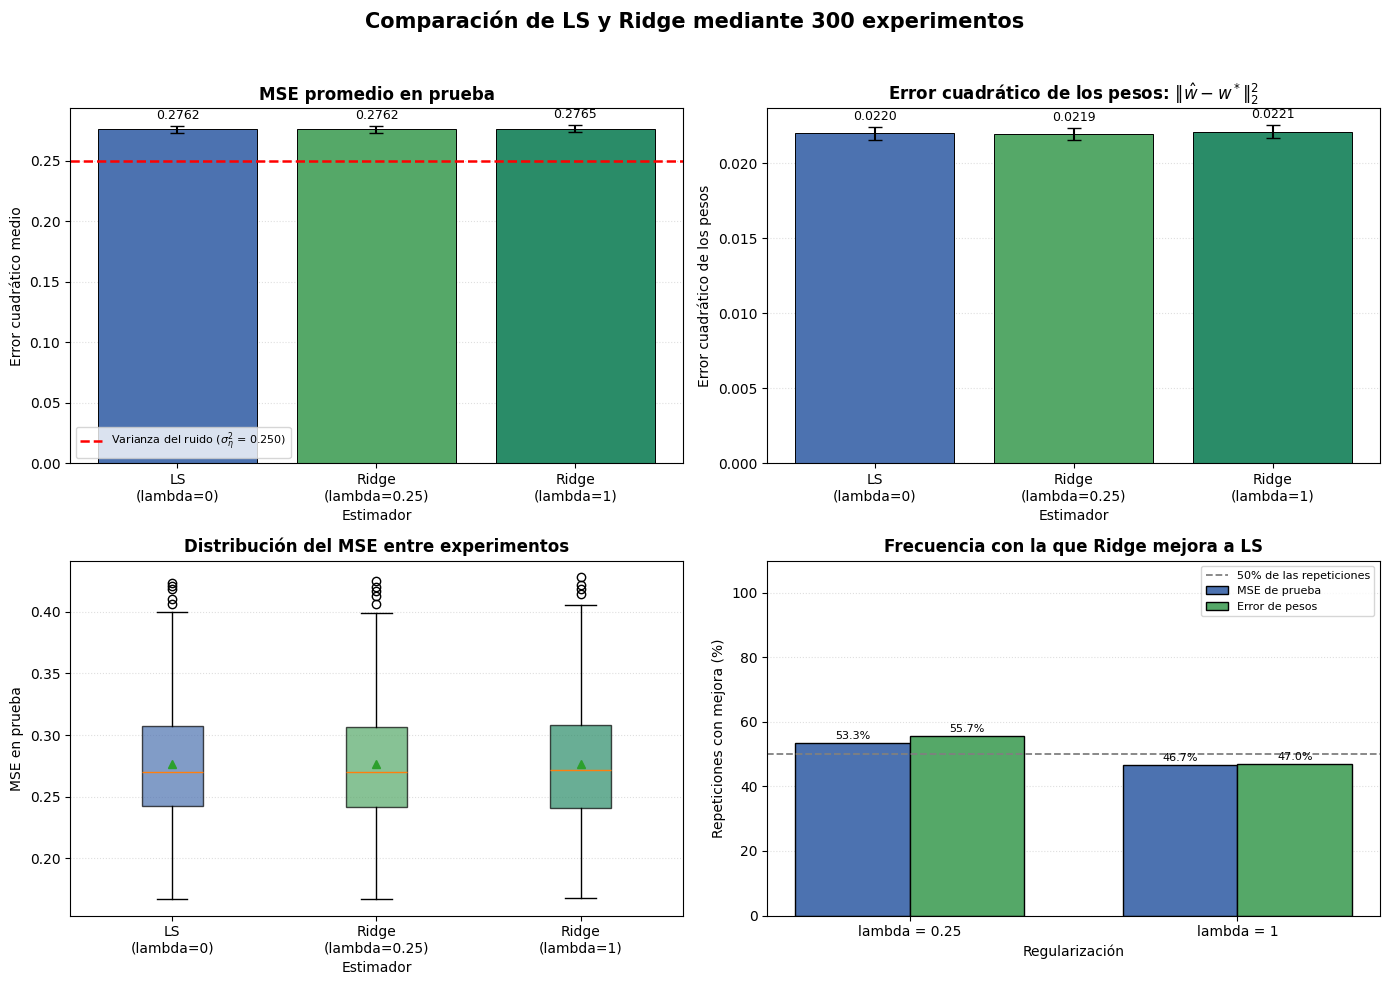

In [ ]:

# ============================================================
# 1.5.4 COMPARACIÓN ESTADÍSTICA DE LS Y RIDGE
# Repetición del experimento con 300 semillas
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------- Parámetros del experimento ----------------
N_REPS = 300
SEED_BASE = 1000

LAMBDAS = (0.0, 0.25, 1.0)

# Etiquetas y colores para identificar cada estimador
NOMBRES = [
    "LS\n(lambda=0)",
    "Ridge\n(lambda=0.25)",
    "Ridge\n(lambda=1)"
]

COLORES = ["#4C72B0", "#55A868", "#2A8C68"]


# ---------------- 1. Función de un experimento ----------------
def un_experimento(seed, lams=LAMBDAS):

    # Generador aleatorio independiente para cada semilla
    rng = np.random.default_rng(seed)

    # Generación de datos
    Xs = rng.standard_normal((N, P))
    F, _ = feature_map(Xs)

    # Pesos verdaderos y observaciones con ruido
    w_true = rng.standard_normal(Q)
    ts = F @ w_true + sigma_eta * rng.standard_normal(N)

    # Partición aleatoria de entrenamiento y prueba
    indices = rng.permutation(N)
    idx_tr = indices[:n_tr]
    idx_te = indices[n_tr:]

    F_tr = F[idx_tr]
    F_te = F[idx_te]

    t_tr = ts[idx_tr]
    t_te = ts[idx_te]

    # Matrices comunes para calcular Ridge
    G = F_tr.T @ F_tr
    b = F_tr.T @ t_tr
    I = np.eye(Q)

    resultados = []

    for lam in lams:

        # LS: solución por mínimos cuadrados
        # lstsq evita resolver directamente las ecuaciones normales
        if np.isclose(lam, 0.0):
            w_hat = np.linalg.lstsq(
                F_tr, t_tr, rcond=None
            )[0]

        # Ridge: mínimos cuadrados regularizados
        else:
            w_hat = np.linalg.solve(
                G + lam * I, b
            )

        # Predicción sobre datos que no se usaron para entrenar
        t_pred = F_te @ w_hat

        # 1. Error cuadrático medio en prueba
        mse_test = np.mean((t_te - t_pred) ** 2)

        # 2. Error cuadrático de los pesos verdaderos
        error_pesos2 = np.sum((w_hat - w_true) ** 2)

        # 3. Norma cuadrática de los pesos estimados
        norma_pesos2 = np.sum(w_hat ** 2)

        resultados.append([
            mse_test,
            error_pesos2,
            norma_pesos2
        ])

    return np.array(resultados)


# ---------------- 2. Repetición de los experimentos ----------------
R = np.stack([
    un_experimento(SEED_BASE + s)
    for s in range(N_REPS)
])

# Dimensiones de R:
# (300 experimentos, 3 estimadores, 3 métricas)

MSE = R[:, :, 0]
ERROR_PESOS2 = R[:, :, 1]
NORMA_PESOS2 = R[:, :, 2]


# ---------------- 3. Resumen estadístico ----------------
# Error estándar de la media = desviación estándar / sqrt(n)

def error_estandar(datos):
    return datos.std(axis=0, ddof=1) / np.sqrt(datos.shape[0])


media_mse = MSE.mean(axis=0)
ee_mse = error_estandar(MSE)

media_error_pesos = ERROR_PESOS2.mean(axis=0)
ee_error_pesos = error_estandar(ERROR_PESOS2)

media_norma_pesos = NORMA_PESOS2.mean(axis=0)


# Porcentaje de repeticiones en las que Ridge supera a LS
mejora_mse = [
    np.nan
    if j == 0
    else 100 * np.mean(MSE[:, j] < MSE[:, 0])
    for j in range(len(LAMBDAS))
]

mejora_pesos = [
    np.nan
    if j == 0
    else 100 * np.mean(
        ERROR_PESOS2[:, j] < ERROR_PESOS2[:, 0]
    )
    for j in range(len(LAMBDAS))
]


# ---------------- 4. Tabla comparativa visual ----------------
tabla = pd.DataFrame({
    "Estimador": ["LS", "Ridge", "Ridge"],
    "Lambda": LAMBDAS,
    "MSE prueba (media)": media_mse,
    "EE del MSE": ee_mse,
    "Error pesos^2 (media)": media_error_pesos,
    "EE error pesos^2": ee_error_pesos,
    "||w_hat||^2 (media)": media_norma_pesos,
    "Mejora MSE vs LS (%)": mejora_mse,
    "Mejora pesos vs LS (%)": mejora_pesos
})

print("\n" + "=" * 105)
print("RESULTADOS PROMEDIO DE LOS 300 EXPERIMENTOS")
print("=" * 105)

display(
    tabla.style
    .format({
        "Lambda": "{:.2f}",
        "MSE prueba (media)": "{:.5f}",
        "EE del MSE": "{:.5f}",
        "Error pesos^2 (media)": "{:.5f}",
        "EE error pesos^2": "{:.5f}",
        "||w_hat||^2 (media)": "{:.5f}",
        "Mejora MSE vs LS (%)":
            lambda x: "—" if pd.isna(x) else f"{x:.1f}%",
        "Mejora pesos vs LS (%)":
            lambda x: "—" if pd.isna(x) else f"{x:.1f}%"
    })
    .background_gradient(
        cmap="Blues",
        subset=["MSE prueba (media)", "Error pesos^2 (media)"]
    )
    .set_caption(
        "Comparación estadística entre LS y Ridge"
    )
)

print(f"\nNúmero de repeticiones: {N_REPS}")
print(f"Varianza teórica del ruido: sigma_eta^2 = {sigma_eta**2:.5f}")

print(
    f"\nRidge (lambda=1) mejora a LS en MSE de prueba en "
    f"{mejora_mse[2]:.1f}% de las repeticiones."
)

print(
    f"Ridge (lambda=1) mejora a LS en error de pesos en "
    f"{mejora_pesos[2]:.1f}% de las repeticiones."
)


# ============================================================
# 1.5.5 FIGURAS COMPARATIVAS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ---------------- Gráfica 1: MSE promedio ----------------
ax = axes[0, 0]

barras = ax.bar(
    NOMBRES,
    media_mse,
    yerr=ee_mse,
    capsize=5,
    color=COLORES,
    edgecolor="black",
    linewidth=0.7
)

# Referencia: varianza del ruido
ax.axhline(
    sigma_eta**2,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label=fr"Varianza del ruido ($\sigma_\eta^2$ = {sigma_eta**2:.3f})"
)

for barra, valor, ee in zip(barras, media_mse, ee_mse):
    ax.annotate(
        f"{valor:.4f}",
        xy=(barra.get_x() + barra.get_width() / 2,
            valor + ee),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title("MSE promedio en prueba", fontsize=12, fontweight="bold")
ax.set_ylabel("Error cuadrático medio")
ax.set_xlabel("Estimador")
ax.legend(fontsize=8)
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)


# ---------------- Gráfica 2: error de estimación de pesos ----------------
ax = axes[0, 1]

barras = ax.bar(
    NOMBRES,
    media_error_pesos,
    yerr=ee_error_pesos,
    capsize=5,
    color=COLORES,
    edgecolor="black",
    linewidth=0.7
)

for barra, valor, ee in zip(
    barras, media_error_pesos, ee_error_pesos
):
    ax.annotate(
        f"{valor:.4f}",
        xy=(barra.get_x() + barra.get_width() / 2,
            valor + ee),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    r"Error cuadrático de los pesos: $\|\hat{w}-w^*\|_2^2$",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("Error cuadrático de los pesos")
ax.set_xlabel("Estimador")
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)


# ---------------- Gráfica 3: distribución del MSE ----------------
ax = axes[1, 0]

cajas = ax.boxplot(
    [MSE[:, j] for j in range(len(LAMBDAS))],
    labels=NOMBRES,
    patch_artist=True,
    showmeans=True
)

for caja, color in zip(cajas["boxes"], COLORES):
    caja.set_facecolor(color)
    caja.set_alpha(0.70)

ax.set_title(
    "Distribución del MSE entre experimentos",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("MSE en prueba")
ax.set_xlabel("Estimador")
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)


# ---------------- Gráfica 4: porcentaje de mejora frente a LS ----------------
ax = axes[1, 1]

x = np.arange(len(LAMBDAS) - 1)
ancho = 0.35

mejora_mse_ridge = np.array([
    100 * np.mean(MSE[:, j] < MSE[:, 0])
    for j in range(1, len(LAMBDAS))
])

mejora_pesos_ridge = np.array([
    100 * np.mean(
        ERROR_PESOS2[:, j] < ERROR_PESOS2[:, 0]
    )
    for j in range(1, len(LAMBDAS))
])

barras_mse = ax.bar(
    x - ancho / 2,
    mejora_mse_ridge,
    ancho,
    label="MSE de prueba",
    color="#4C72B0",
    edgecolor="black"
)

barras_pesos = ax.bar(
    x + ancho / 2,
    mejora_pesos_ridge,
    ancho,
    label="Error de pesos",
    color="#55A868",
    edgecolor="black"
)

# Referencia: mejorar en más de la mitad de los experimentos
ax.axhline(
    50,
    color="gray",
    linestyle="--",
    linewidth=1.3,
    label="50% de las repeticiones"
)

for grupo in [barras_mse, barras_pesos]:
    for barra in grupo:
        alto = barra.get_height()
        ax.annotate(
            f"{alto:.1f}%",
            xy=(barra.get_x() + barra.get_width() / 2, alto),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

ax.set_title(
    "Frecuencia con la que Ridge mejora a LS",
    fontsize=12,
    fontweight="bold"
)
ax.set_ylabel("Repeticiones con mejora (%)")
ax.set_xlabel("Regularización")
ax.set_xticks(x)
ax.set_xticklabels([
    f"lambda = {lam:g}" for lam in LAMBDAS[1:]
])
ax.set_ylim(0, 110)
ax.legend(fontsize=8)
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)


# ---------------- Presentación final ----------------
fig.suptitle(
    "Comparación de LS y Ridge mediante 300 experimentos",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


#### Análisis de resultados

**Coincidencias esperadas.**

1. **Mínimos cuadrados $\equiv$ máxima verosimilitud.** Con ruido gaussiano i.i.d., $-\ell(w)=\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|^2+\text{cte}$ (1.3). Las dos estimaciones coinciden hasta $\sim10^{-9}$ en norma (se ve en la salida de arriba).
2. **Ridge $\equiv$ MAP.** Con $\lambda=\sigma_\eta^2/\sigma_w^2=1$ ($\sigma_w^2=0.25$), el log-posterior negativo es $\frac{1}{2\sigma_\eta^2}J_\lambda(w)$ (1.4). Coinciden también hasta $\sim10^{-9}$.
3. **Forma primal $\equiv$ dual** (kernel trick de 1.2): coinciden a $\sim10^{-14}$.

**Discrepancias numéricas.** LS y Ridge se calculan con una solución directa del sistema lineal, bien condicionado ($\mathrm{cond}(\Phi^\top\Phi)\approx17$), con error de redondeo $\sim10^{-14}$. ML y MAP se obtienen con un optimizador iterativo (L-BFGS-B) que se detiene por tolerancia, no por igualdad exacta; el residuo de $\sim10^{-9}$ es de optimización, no de modelo.

**Entrenamiento vs. prueba.** El MSE de entrenamiento ($\approx0.24$) queda por debajo de $\sigma_\eta^2=0.25$ y el de prueba ($\approx0.28$) por encima. Es lo esperado: el ajuste de $Q=20$ parámetros absorbe parte del ruido de entrenamiento ($\mathbb{E}[\text{MSE}_{tr}]\approx\sigma_\eta^2\frac{N_{tr}-Q}{N_{tr}}\approx0.23$) y generaliza peor ($\mathbb{E}[\text{MSE}_{te}]\approx\sigma_\eta^2(1+\frac{Q}{N_{tr}-Q-1})\approx0.27$). El piso irreducible del error de prueba es $\sigma_\eta^2=0.25$.

**LS vs. Ridge: ¿cuál es mejor?** En esta partición Ridge tiene un MSE de prueba algo menor pero un error de parámetros $\|\hat w-w^\ast\|$ algo mayor; son diferencias del orden de $10^{-2}$ y de signo contrario, por lo que **no son concluyentes** con solo 60 datos de prueba. La repetición con 300 semillas lo confirma: las medias de LS y Ridge son prácticamente iguales (dentro de un error estándar; Ridge con $\lambda=1$ es incluso marginalmente peor) y Ridge($\lambda=1$) solo supera a LS en menos de la mitad de las repeticiones ($\approx47\,\%$). La razón es estructural: aquí $N_{tr}=240\gg Q=20$, los autovalores de $\Phi^\top\Phi$ son grandes frente a $\lambda=1$ (factores de encogimiento entre $\approx0.99$ y $\approx1.00$), y el ruido es moderado. La regularización solo marca diferencia cuando $\Phi^\top\Phi$ está mal condicionada, hay pocos datos frente a $Q$ o el ruido es grande.

**Sobre el prior compatible.** $\sigma_w^2=0.25$ es mucho más estrecho que la distribución con la que se generó $w^\ast$ ($\mathcal{N}(0,1)$): el prior es *desajustado*, y el $\lambda$ bayesianamente coherente con los datos sería $\sigma_\eta^2/1=0.25$. Como el efecto de $\lambda$ es pequeño, esto no cambia las conclusiones.

# Pregunta 2: Espacios RKHS, embeddings de media y discrepancia entre distribuciones

> **Enunciado.** Sea $k:\chi\times\chi\to\mathbb{R}$ un kernel simétrico definido positivo y $\mathcal{H}_k$ el espacio de Hilbert con núcleo reproductor asociado.

**Los cuatro niveles que se distinguen en esta pregunta.**

| Nivel | Objeto | Detalle |
|---|---|---|
| Espacio original | $\chi$ (p. ej. $\mathbb{R}^{784}$ para imágenes $28\times28$) | donde viven los datos $x_i$ |
| Espacio de características | $\phi(x)=k(x,\cdot)\in\mathcal{H}_k$ | mapeo canónico; posiblemente de dimensión infinita ($Q\to\infty$) |
| RKHS | $\mathcal{H}_k$ con $\langle\cdot,\cdot\rangle_{\mathcal{H}_k}$ | **propiedad reproductora:** $f(x)=\langle f,k(x,\cdot)\rangle$ y $\langle\phi(x),\phi(x')\rangle=k(x,x')$ |
| Formulación matricial inducida | $K_{ij}=k(x_i,x_j)\in\mathbb{R}^{n\times n}$ | solo con $K$ se calculan normas y distancias en $\mathcal{H}_k$ sin construir $\phi$ |

## 2.1 Embedding de media

> **Enunciado.** Defina rigurosamente el embedding de media asociado a una variable aleatoria $X$: $\mu_k=\mathbb{E}[k(X,\cdot)]$.

Sea $X$ una variable aleatoria con distribución $P_X$ sobre $\chi$, y $k$ medible. Se supone la condición de integrabilidad

$$\mathbb{E}\big[\sqrt{k(X,X)}\big]<\infty\qquad(\text{se cumple siempre si }k\text{ es acotado, p. ej. el gaussiano: }k(x,x)=1).$$

**Definición.** El *embedding de media* de $X$ es el elemento $\mu_k\in\mathcal{H}_k$ definido por la integral de Bochner

$$\mu_k:=\mathbb{E}\big[k(X,\cdot)\big]=\int_\chi k(x,\cdot)\,dP_X(x)=\mathbb{E}[\phi(X)],$$

o, equivalentemente, de forma *débil*, como el único elemento de $\mathcal{H}_k$ que cumple

$$\langle f,\mu_k\rangle_{\mathcal{H}_k}=\mathbb{E}[f(X)]\qquad\text{para todo }f\in\mathcal{H}_k .$$

Tomando $f=k(x,\cdot)$ y usando la propiedad reproductora, $\mu_k$ evaluado en un punto es

$$\mu_k(x)=\langle\mu_k,k(x,\cdot)\rangle=\mathbb{E}[k(X,x)] .$$

**Versión empírica.** Para una muestra $\{x_i\}_{i=1}^n$ con medida empírica $\hat P=\frac1n\sum_i\delta_{x_i}$:

$$\hat\mu_k=\frac1n\sum_{i=1}^nk(x_i,\cdot)\in\mathcal{H}_k,\qquad \|\hat\mu_k\|^2_{\mathcal{H}_k}=\frac{1}{n^2}\sum_{i,j}k(x_i,x_j)=\frac{1}{n^2}\mathbf{1}_n^\top K\mathbf{1}_n,\quad K\in\mathbb{R}^{n\times n}.$$

Es el análogo en $\mathcal{H}_k$ de $\mathbb{E}\{\Phi(X)\}\approx\frac1N\mathbf{1}_N^\top\Phi\in\mathbb{R}^{1\times Q}$ ($Q\to\infty$) visto en clase.

## 2.2 Por qué $\mu_k\in\mathcal{H}_k$ e interpretación geométrica

> **Enunciado.** Explique por qué $\mu_k\in\mathcal{H}_k$ e interprete geométricamente su significado como representante de la distribución de $X$.

#### Por qué pertenece a $\mathcal{H}_k$

Se considera el funcional lineal $L(f)=\mathbb{E}[f(X)]$ sobre $\mathcal{H}_k$. Por la propiedad reproductora y Cauchy–Schwarz,

$$|f(x)|=|\langle f,k(x,\cdot)\rangle|\le\|f\|_{\mathcal{H}_k}\sqrt{k(x,x)}\ \Rightarrow\ |L(f)|\le\mathbb{E}|f(X)|\le\|f\|_{\mathcal{H}_k}\,\mathbb{E}\big[\sqrt{k(X,X)}\big]<\infty .$$

Luego $L$ es **lineal y acotado**. Como $\mathcal{H}_k$ es de Hilbert, el **teorema de representación de Riesz** garantiza un único $\mu_k\in\mathcal{H}_k$ con $L(f)=\langle f,\mu_k\rangle$, y ese elemento coincide con $\mathbb{E}[k(X,\cdot)]$ (se verifica evaluando en $k(x,\cdot)$, como en 2.1). Alternativamente, $k(X,\cdot)$ es una variable aleatoria con valores en un espacio de Hilbert completo con $\mathbb{E}\|k(X,\cdot)\|=\mathbb{E}\sqrt{k(X,X)}<\infty$, por lo que su integral de Bochner existe en $\mathcal{H}_k$. La clave es que $\mathcal{H}_k$ sea completo y que la norma esté controlada por $\sqrt{k(x,x)}$.

#### Interpretación geométrica

- **Centroide.** $\phi(X)=k(X,\cdot)$ es una nube de puntos en $\mathcal{H}_k$; $\mu_k$ es su **centro de masa**, y pertenece a la envoltura convexa cerrada de $\{k(x,\cdot)\}$. En la versión empírica es literalmente el promedio de los $n$ puntos transformados.
- **Resume todos los valores esperados.** $\langle f,\mu_k\rangle=\mathbb{E}[f(X)]$: $\mu_k$ codifica, de una sola vez, la esperanza de *toda* función $f\in\mathcal{H}_k$ (con un kernel lineal solo la media; con un kernel polinómico, momentos hasta cierto orden; con un kernel gaussiano, infinitos momentos).
- **Representante de la distribución.** Si $k$ es *característico* (p. ej. el gaussiano) la aplicación $P\mapsto\mu_P$ es inyectiva: $\mu_P=\mu_Q\iff P=Q$. Entonces la distribución $P$ queda representada por **un punto** de $\mathcal{H}_k$, y comparar distribuciones se reduce a medir distancias entre puntos (es lo que se hace en 2.3).
- **Norma.** $\|\mu_k\|^2=\mathbb{E}[k(X,X')]$ con $X'$ copia independiente. Para el kernel gaussiano todo $\phi(x)$ está en la esfera unitaria ($\|\phi(x)\|^2=k(x,x)=1$), así que $\|\mu_k\|\le1$ (promedio de puntos de la esfera cae dentro de la bola), con igualdad solo si $X$ es determinista. Una distribución muy concentrada tiene $\|\mu_k\|$ cercana a 1 y una muy dispersa, cercana a 0.

## 2.3 Discrepancia máxima de medias (MMD) y forma matricial

> **Enunciado.** Sean $X\sim P_X$ y $Y\sim P_Y$ independientes, con $\mu_X=\mathbb{E}[k(X,\cdot)]$, $\mu_Y=\mathbb{E}[k(Y,\cdot)]$ y $\mathrm{MMD}^2(P_X,P_Y)=\|\mu_X-\mu_Y\|^2_{\mathcal{H}_k}$. Con muestras $\{x_i\}_{i=1}^n$, $\{y_j\}_{j=1}^m$, demuestre que el estimador empírico sesgado es
> $$\widehat{\mathrm{MMD}}^2_b=\frac{1}{n^2}\mathbf{1}_n^\top K_{XX}\mathbf{1}_n+\frac{1}{m^2}\mathbf{1}_m^\top K_{YY}\mathbf{1}_m-\frac{2}{nm}\mathbf{1}_n^\top K_{XY}\mathbf{1}_m .$$

#### Paso 1: expansión de la norma (formulación poblacional)

Por bilinealidad y simetría del producto interno de $\mathcal{H}_k$:

$$\|\mu_X-\mu_Y\|^2=\langle\mu_X-\mu_Y,\mu_X-\mu_Y\rangle=\langle\mu_X,\mu_X\rangle-2\langle\mu_X,\mu_Y\rangle+\langle\mu_Y,\mu_Y\rangle .$$

#### Paso 2: cada producto interno se convierte en kernel (propiedad reproductora)

El producto interno es continuo y la esperanza (integral de Bochner) conmuta con funcionales lineales continuos. Para variables **independientes** $X,Y$ (y $X'$, $Y'$ copias independientes de $X$, $Y$):

$$\langle\mu_X,\mu_Y\rangle=\big\langle\mathbb{E}_X k(X,\cdot),\,\mathbb{E}_Yk(Y,\cdot)\big\rangle=\mathbb{E}_X\mathbb{E}_Y\big\langle k(X,\cdot),k(Y,\cdot)\big\rangle=\mathbb{E}[k(X,Y)],$$

donde la última igualdad es la propiedad reproductora $\langle k(x,\cdot),k(y,\cdot)\rangle=k(x,y)$. Análogamente $\langle\mu_X,\mu_X\rangle=\mathbb{E}[k(X,X')]$ y $\langle\mu_Y,\mu_Y\rangle=\mathbb{E}[k(Y,Y')]$. Así, la **cantidad poblacional** es

$$\mathrm{MMD}^2(P_X,P_Y)=\mathbb{E}[k(X,X')]-2\,\mathbb{E}[k(X,Y)]+\mathbb{E}[k(Y,Y')]\ \ge0 .$$

#### Paso 3: versión empírica

Se sustituyen $\mu_X,\mu_Y$ por sus embeddings empíricos $\hat\mu_X=\frac1n\sum_ik(x_i,\cdot)$ y $\hat\mu_Y=\frac1m\sum_jk(y_j,\cdot)$ y se desarrollan los productos internos con linealidad y la propiedad reproductora:

$$\langle\hat\mu_X,\hat\mu_X\rangle=\frac1{n^2}\sum_{i=1}^n\sum_{i'=1}^n\langle k(x_i,\cdot),k(x_{i'},\cdot)\rangle=\frac1{n^2}\sum_{i,i'}k(x_i,x_{i'}),$$

$$\langle\hat\mu_Y,\hat\mu_Y\rangle=\frac1{m^2}\sum_{j,j'}k(y_j,y_{j'}),\qquad\langle\hat\mu_X,\hat\mu_Y\rangle=\frac1{nm}\sum_{i=1}^n\sum_{j=1}^mk(x_i,y_j).$$

#### Paso 4: forma matricial

Se definen las matrices de Gram $(K_{XX})_{ii'}=k(x_i,x_{i'})\in\mathbb{R}^{n\times n}$, $(K_{YY})_{jj'}=k(y_j,y_{j'})\in\mathbb{R}^{m\times m}$ y $(K_{XY})_{ij}=k(x_i,y_j)\in\mathbb{R}^{n\times m}$. Para cualquier $A\in\mathbb{R}^{a\times b}$ se tiene $\mathbf{1}_a^\top A\mathbf{1}_b=\sum_{i,j}A_{ij}$, pues $(A\mathbf{1}_b)_i=\sum_jA_{ij}$ y luego $\mathbf{1}_a^\top(\cdot)$ suma sobre $i$. Por tanto

$$\boxed{\widehat{\mathrm{MMD}}^2_b=\frac{1}{n^2}\mathbf{1}_n^\top K_{XX}\mathbf{1}_n+\frac{1}{m^2}\mathbf{1}_m^\top K_{YY}\mathbf{1}_m-\frac{2}{nm}\mathbf{1}_n^\top K_{XY}\mathbf{1}_m}\ \blacksquare$$

**Dimensiones de cada término.**

| Término | Producto | Dimensión | Resultado |
|---|---|---|---|
| $\mathbf{1}_n^\top K_{XX}\mathbf{1}_n$ | $(1\times n)(n\times n)(n\times1)$ | $1\times1$ | escalar (suma de las $n^2$ entradas) |
| $\mathbf{1}_m^\top K_{YY}\mathbf{1}_m$ | $(1\times m)(m\times m)(m\times1)$ | $1\times1$ | escalar ($m^2$ entradas) |
| $\mathbf{1}_n^\top K_{XY}\mathbf{1}_m$ | $(1\times n)(n\times m)(m\times1)$ | $1\times1$ | escalar ($nm$ entradas) |

Cada término es un **promedio** de las entradas del bloque correspondiente de la Gram conjunta de las $n+m$ muestras. Una forma compacta equivalente: con $a=\big[\tfrac1n\mathbf{1}_n;\,-\tfrac1m\mathbf{1}_m\big]\in\mathbb{R}^{n+m}$ y $K=\begin{bmatrix}K_{XX}&K_{XY}\\K_{XY}^\top&K_{YY}\end{bmatrix}$, $\widehat{\mathrm{MMD}}^2_b=a^\top Ka=\|\hat\mu_X-\hat\mu_Y\|^2\ge0$ (se usa en el código para la prueba de permutación).

#### Estimador sesgado vs. formulación poblacional

- **Poblacional:** $\mathrm{MMD}^2=\mathbb{E}[k(X,X')]-2\mathbb{E}[k(X,Y)]+\mathbb{E}[k(Y,Y')]$, un número fijo que es $0$ si y solo si $P_X=P_Y$ (kernel característico).
- **Empírico sesgado (estadístico V):** incluye en $\mathbf{1}^\top K_{XX}\mathbf{1}$ los términos de la diagonal $i=i'$, donde $k(x_i,x_i)$ es una autocomparación, no una comparación entre dos observaciones independientes. Como $\mathbb{E}\big[\frac1{n^2}\sum_{i,i'}k(x_i,x_{i'})\big]=\frac1n\mathbb{E}[k(X,X)]+\big(1-\frac1n\big)\mathbb{E}[k(X,X')]$,

$$\mathbb{E}\big[\widehat{\mathrm{MMD}}^2_b\big]=\mathrm{MMD}^2+\frac1n\big(\mathbb{E}[k(X,X)]-\mathbb{E}[k(X,X')]\big)+\frac1m\big(\mathbb{E}[k(Y,Y)]-\mathbb{E}[k(Y,Y')]\big).$$

  Con el kernel gaussiano ($k(x,x)=1\ge k(x,x')$) el sesgo es **no negativo**: incluso si $P_X=P_Y$ el estimador sesgado da un valor $>0$ del orden de $\frac1n+\frac1m$ por la distancia media entre puntos. Además $\widehat{\mathrm{MMD}}^2_b\ge0$ siempre (es una norma cuadrada).
- **Empírico insesgado** (excluye la diagonal): $\widehat{\mathrm{MMD}}^2_u=\frac{\mathbf{1}^\top K_{XX}\mathbf{1}-\mathrm{tr}K_{XX}}{n(n-1)}+\frac{\mathbf{1}^\top K_{YY}\mathbf{1}-\mathrm{tr}K_{YY}}{m(m-1)}-\frac{2}{nm}\mathbf{1}^\top K_{XY}\mathbf{1}$; tiene esperanza $\mathrm{MMD}^2$ exacta, pero puede ser negativo en muestras finitas.

---
# 2.4 Implementación de MMD con MNIST

**Objetivo.** Aplicar el estimador empírico sesgado de la discrepancia máxima de medias, definido en 2.3, a distintas muestras del **mismo conjunto MNIST**. No se compara MNIST con otro dataset.

Para dos grupos de imágenes $X=\{x_i\}_{i=1}^n$ y $Y=\{y_j\}_{j=1}^m$, la fórmula es

$$
\widehat{\mathrm{MMD}}_b^2(X,Y)=\frac{1}{n^2}\mathbf{1}_n^\top K_{XX}\mathbf{1}_n+\frac{1}{m^2}\mathbf{1}_m^\top K_{YY}\mathbf{1}_m-\frac{2}{nm}\mathbf{1}_n^\top K_{XY}\mathbf{1}_m.
$$

Cada imagen $28\times28$ se aplana a un vector de 784 píxeles normalizados en $[0,1]$. El kernel gaussiano es

$$k(u,v)=\exp\!\left(-\frac{\|u-v\|_2^2}{2\sigma^2}\right).$$

**Plan de la sección:** cargar MNIST; seleccionar dos mitades disjuntas; definir el kernel y el estimador; elegir $\sigma$ mediante la mediana de distancias; calcular una MMD de referencia entre las dos mitades; estudiar la sensibilidad a $\sigma$; y finalmente comparar las distribuciones de los dígitos 0–9 dentro de MNIST.

### Explicación — 2.4.1 Cargar MNIST

- `torchvision.datasets.MNIST` descarga o reutiliza el conjunto de entrenamiento de MNIST.
- `transforms.ToTensor()` convierte cada imagen a un tensor de forma `1 × 28 × 28` y normaliza los píxeles a $[0,1]$.
- En la comparación entre dos grupos de MNIST no se utilizan las etiquetas. Se reservan únicamente para la subsección final, donde se agrupan imágenes por dígito.

**Qué mirar:** número de imágenes disponibles y forma de una imagen de ejemplo. En Google Colab, la primera ejecución necesita conexión a internet para descargar el dataset.

In [ ]:
# ============================================================
# 2.4.1 CARGAR MNIST
# ============================================================
from torchvision import datasets, transforms

DATA_DIR = "data_torchvision"             # carpeta de caché local de la descarga
to_tensor = transforms.ToTensor()         # imagen PIL -> tensor 1x28x28 con píxeles en [0,1]

print("Descargando / cargando MNIST ...")
mnist_ds = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=to_tensor
)

print(f"MNIST: {len(mnist_ds):,} imágenes de entrenamiento")
print("Forma de una imagen:", mnist_ds[0][0].shape)
print("Etiqueta de ejemplo (se usará solo para agrupar por dígito al final):", int(mnist_ds[0][1]))

Descargando / cargando MNIST ...


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 508kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.61MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.24MB/s]

MNIST: 60,000 imágenes de entrenamiento
Forma de una imagen: torch.Size([1, 28, 28])
Etiqueta de ejemplo (se usará solo para agrupar por dígito al final): 5


### Explicación — 2.4.2 Seleccionar 1 000 imágenes y formar dos grupos

La función `tomar_imagenes` elige 1 000 índices **sin reemplazo** y aplana cada imagen de `1 × 28 × 28` a 784 componentes. Luego se forman `mnist_A` y `mnist_B`, con 500 imágenes cada uno y sin índices repetidos entre los dos grupos.

Ambos grupos proceden del mismo conjunto de entrenamiento; por eso esta comparación sirve como **referencia muestral** para observar el valor que puede dar el estimador cuando no se pretende comparar dos datasets distintos.

In [ ]:
# ============================================================
# 2.4.2 MUESTRA DE 1 000 IMÁGENES -> DOS GRUPOS DE 500
# ============================================================
SEED_MMD = 2026


def tomar_imagenes(ds, n_total=1000, seed=SEED_MMD):
    """Selecciona imágenes sin repetición y las aplana a vectores de 784 píxeles."""
    rng_local = np.random.default_rng(seed)
    indices = rng_local.choice(len(ds), size=n_total, replace=False)
    X_muestra = np.zeros((n_total, 784), dtype=np.float64)

    for k, idx in enumerate(indices):
        X_muestra[k] = ds[int(idx)][0].numpy().reshape(-1)

    return X_muestra, indices


mnist_1000, indices_mnist = tomar_imagenes(mnist_ds, n_total=1000, seed=SEED_MMD)
mnist_A = mnist_1000[:500]
mnist_B = mnist_1000[500:]

print("mnist_A:", mnist_A.shape)
print("mnist_B:", mnist_B.shape)
print("Grupos disjuntos:", len(set(indices_mnist[:500]) & set(indices_mnist[500:])) == 0)
print("Píxeles en [0,1]:", 0.0 <= mnist_1000.min() and mnist_1000.max() <= 1.0)

mnist_A: (500, 784)
mnist_B: (500, 784)
Grupos disjuntos: True
Píxeles en [0,1]: True


### Explicación — 2.4.3 Visualizar algunas imágenes

Se muestran ocho imágenes del grupo A. `reshape(28, 28)` devuelve la estructura bidimensional original y `imshow` las dibuja en escala de grises. Esta celda es una comprobación visual de que los datos se cargaron y normalizaron correctamente.

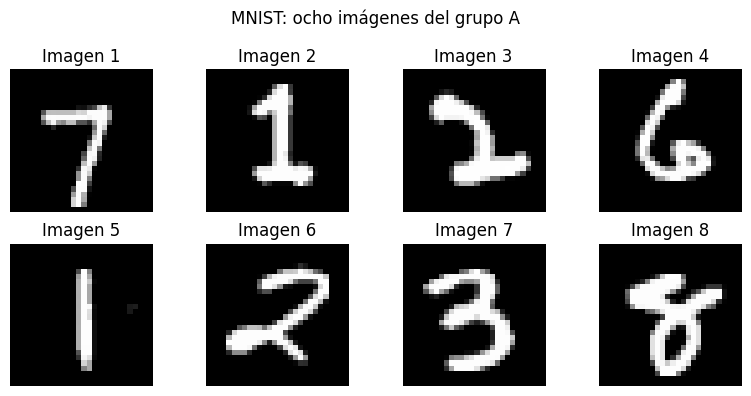

In [ ]:
# ============================================================
# 2.4.3 VISUALIZAR OCHO IMÁGENES DE MNIST
# ============================================================
def mostrar_imagenes(X, titulo, n=8):
    fig, axes = plt.subplots(2, 4, figsize=(8, 4))
    fig.suptitle(titulo)

    for ax, k in zip(axes.ravel(), range(n)):
        ax.imshow(X[k].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Imagen {k + 1}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


mostrar_imagenes(mnist_A, "MNIST: ocho imágenes del grupo A")

### Explicación — 2.4.4 Kernel gaussiano y estimador de MMD²

1. `kernel_gaussiano(U, V, sigma)` crea la matriz de Gram con entradas $K_{ij}=k(u_i,v_j)$. Usa la identidad
   $$\|u-v\|^2=\|u\|^2+\|v\|^2-2u^\top v$$
   y operaciones matriciales, sin calcular cada par mediante bucles anidados.
2. `np.maximum(..., 0)` corrige distancias cuadradas negativas diminutas que pueden aparecer por redondeo.
3. `mmd2_sesgado` implementa exactamente los tres términos de la fórmula matricial de 2.3. El estimador es **sesgado** porque incluye la diagonal de $K_{XX}$ y $K_{YY}$.

**Dimensiones:** con 500 imágenes en cada grupo, $K_{XX}$, $K_{YY}$ y $K_{XY}$ tienen forma $500\times500$.

In [ ]:
# ============================================================
# 2.4.4 KERNEL GAUSSIANO Y ESTIMADOR SESGADO DE MMD^2
# ============================================================
def kernel_gaussiano(U, V, sigma):
    """Matriz K[i,j] = exp(-||U[i]-V[j]||^2 / (2*sigma^2))."""
    u2 = np.sum(U * U, axis=1)[:, None]        # forma (n, 1)
    v2 = np.sum(V * V, axis=1)[None, :]        # forma (1, m)
    dist2 = np.maximum(u2 + v2 - 2.0 * (U @ V.T), 0.0)
    return np.exp(-dist2 / (2.0 * sigma**2))


def mmd2_sesgado(KXX, KYY, KXY):
    """Calcula MMD^2 sesgada a partir de las tres matrices de Gram."""
    n = KXX.shape[0]
    m = KYY.shape[0]
    unos_n = np.ones(n)
    unos_m = np.ones(m)

    termino_xx = (unos_n @ KXX @ unos_n) / n**2
    termino_yy = (unos_m @ KYY @ unos_m) / m**2
    termino_xy = (unos_n @ KXY @ unos_m) / (n * m)

    return float(termino_xx + termino_yy - 2.0 * termino_xy)


def mmd_entre(X, Y, sigma):
    """Construye KXX, KYY, KXY y devuelve el estimador sesgado de MMD^2."""
    KXX = kernel_gaussiano(X, X, sigma)
    KYY = kernel_gaussiano(Y, Y, sigma)
    KXY = kernel_gaussiano(X, Y, sigma)
    return mmd2_sesgado(KXX, KYY, KXY)


print("Funciones definidas: kernel_gaussiano, mmd2_sesgado y mmd_entre")

Funciones definidas: kernel_gaussiano, mmd2_sesgado y mmd_entre


### Explicación — 2.4.5 Elegir el ancho de banda $\sigma$

La heurística de la mediana calcula distancias euclidianas entre pares distintos de una submuestra de imágenes de MNIST y utiliza su mediana como $\sigma$. `np.triu_indices(..., k=1)` conserva únicamente pares $i<j$: excluye la diagonal y evita contar dos veces cada par.

- Si $\sigma$ es muy pequeño, las similitudes entre imágenes distintas tienden a cero y las matrices de Gram se acercan a la identidad.
- Si $\sigma$ es muy grande, las similitudes tienden a uno y las matrices se acercan a una matriz de unos.

En ambos extremos la MMD² pierde capacidad de distinguir diferencias. Se utilizará el mismo $\sigma$ en todas las comparaciones de esta sección.

In [ ]:
# ============================================================
# 2.4.5 ELEGIR SIGMA CON LA MEDIANA DE DISTANCIAS
# ============================================================
rng_sigma = np.random.default_rng(SEED_MMD + 1)
sub_indices = rng_sigma.choice(len(mnist_1000), size=250, replace=False)
sub_mnist = mnist_1000[sub_indices]                        # (250, 784)

normas2 = np.sum(sub_mnist * sub_mnist, axis=1)
dist2_sub = np.maximum(
    normas2[:, None] + normas2[None, :] - 2.0 * (sub_mnist @ sub_mnist.T),
    0.0
)
pares = np.triu_indices(len(sub_mnist), k=1)
distancias = np.sqrt(dist2_sub[pares])
sigma = float(np.median(distancias))

print(f"Número de pares distintos: {len(distancias):,}")
print(f"Distancia mínima: {distancias.min():.4f}")
print(f"Mediana elegida (sigma): {sigma:.6f}")
print(f"Distancia máxima: {distancias.max():.4f}")

Número de pares distintos: 31,125
Distancia mínima: 1.7825
Mediana elegida (sigma): 10.091008
Distancia máxima: 14.4958


### Explicación — 2.4.6 Inspección de las matrices de Gram

Se visualiza una versión pequeña de las matrices para que los patrones sean legibles:

- **$K_{AA}$:** similitudes del grupo A consigo mismo. La diagonal vale 1 porque $k(x,x)=1$.
- **$K_{AB}$:** similitudes entre el grupo A y el grupo B. Como son grupos disjuntos, no aparece una diagonal de unos que compare cada imagen consigo misma.

La comparación de medias es ilustrativa; por sí sola no es un contraste estadístico de hipótesis.

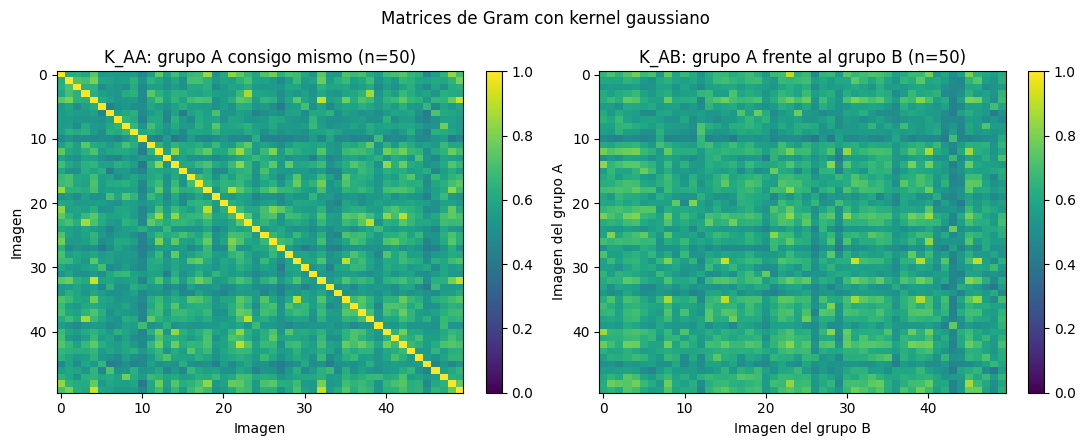

Media de K_AA: 0.601835
Media de K_AB: 0.601322
Diagonal de K_AA igual a 1: True


In [ ]:
# ============================================================
# 2.4.6 MAPAS DE CALOR DE LAS MATRICES DE GRAM
# ============================================================
sub_n = 50
KAA_demo = kernel_gaussiano(mnist_A[:sub_n], mnist_A[:sub_n], sigma)
KAB_demo = kernel_gaussiano(mnist_A[:sub_n], mnist_B[:sub_n], sigma)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
im0 = axes[0].imshow(KAA_demo, vmin=0, vmax=1, aspect="auto")
axes[0].set_title(f"K_AA: grupo A consigo mismo (n={sub_n})")
axes[0].set_xlabel("Imagen")
axes[0].set_ylabel("Imagen")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(KAB_demo, vmin=0, vmax=1, aspect="auto")
axes[1].set_title(f"K_AB: grupo A frente al grupo B (n={sub_n})")
axes[1].set_xlabel("Imagen del grupo B")
axes[1].set_ylabel("Imagen del grupo A")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

fig.suptitle("Matrices de Gram con kernel gaussiano")
plt.tight_layout()
plt.show()

print(f"Media de K_AA: {KAA_demo.mean():.6f}")
print(f"Media de K_AB: {KAB_demo.mean():.6f}")
print("Diagonal de K_AA igual a 1:", np.allclose(np.diag(KAA_demo), 1.0))

### Explicación — 2.4.7 MMD² de referencia dentro de MNIST

Se calcula $\widehat{\mathrm{MMD}}_b^2$ entre los grupos disjuntos A y B con el mismo $\sigma$. Ambos grupos proceden de MNIST, de modo que su distribución de origen es la misma.

El valor **no tiene que ser exactamente cero**: el estimador sesgado incluye la diagonal de las matrices de Gram y presenta un sesgo positivo para el kernel gaussiano. Para $n=m=500$, la cantidad $1/n+1/m=0.004$ es una referencia superior para ese término de sesgo bajo las condiciones del kernel gaussiano; el valor observado también varía por el muestreo.

In [ ]:
# ============================================================
# 2.4.7 MMD^2 DE REFERENCIA: DOS MITADES DE MNIST
# ============================================================
mmd_referencia = mmd_entre(mnist_A, mnist_B, sigma)
limite_diagonal = 1.0 / len(mnist_A) + 1.0 / len(mnist_B)

print(f"MMD^2 sesgada (MNIST A vs MNIST B): {mmd_referencia:.6f}")
print(f"Referencia 1/n + 1/m:              {limite_diagonal:.6f}")
print("Interpretación: las dos muestras proceden del mismo dataset; el valor observado incluye sesgo y variabilidad muestral.")

MMD^2 sesgada (MNIST A vs MNIST B): 0.001409
Referencia 1/n + 1/m:              0.004000
Interpretación: las dos muestras proceden del mismo dataset; el valor observado incluye sesgo y variabilidad muestral.


### Explicación — 2.4.8 Sensibilidad al ancho de banda

Se recalcula la MMD² de referencia con $\sigma/2$, $\sigma$ y $2\sigma$. Esto permite observar que el estimador depende de la escala del kernel.

- Con un $\sigma$ muy pequeño, las matrices de Gram se aproximan a identidades y la MMD² sesgada tiende a $1/n+1/m$ para muestras sin duplicados.
- Con un $\sigma$ muy grande, las entradas de las matrices tienden a uno y la MMD² tiende a cero.

No se debe asumir que cada punto intermedio siga una tendencia estrictamente monótona; se deben interpretar los valores calculados.

sigma x 0.5 = 5.04550 | MMD^2 = 0.003318
sigma x 1.0 = 10.09101 | MMD^2 = 0.001409
sigma x 2.0 = 20.18202 | MMD^2 = 0.000411


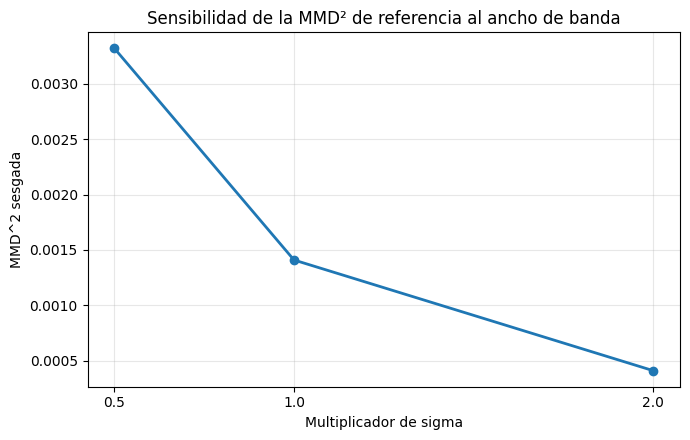

In [ ]:
# ============================================================
# 2.4.8 SENSIBILIDAD A SIGMA
# ============================================================
multiplos_sigma = np.array([0.5, 1.0, 2.0])
mmd_sensibilidad = []

for mult in multiplos_sigma:
    sigma_actual = sigma * mult
    valor = mmd_entre(mnist_A, mnist_B, sigma_actual)
    mmd_sensibilidad.append(valor)
    print(f"sigma x {mult:.1f} = {sigma_actual:.5f} | MMD^2 = {valor:.6f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(multiplos_sigma, mmd_sensibilidad, marker="o", linewidth=2)
ax.set_xlabel("Multiplicador de sigma")
ax.set_ylabel("MMD^2 sesgada")
ax.set_title("Sensibilidad de la MMD² de referencia al ancho de banda")
ax.set_xticks(multiplos_sigma)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Explicación — 2.4.9 Comparar las clases 0–9 dentro de MNIST

Ahora se usan las etiquetas **solo para seleccionar imágenes de cada dígito**. Para cada clase se seleccionan 500 imágenes, se forma una matriz de similitud media y se calcula la MMD² sesgada entre cada par de clases con el mismo $\sigma$.

- **Similitud media:** valores mayores indican mayor similitud media según el kernel.
- **MMD² entre clases:** valores cercanos a cero indican embeddings empíricos más próximos; valores mayores indican mayor separación bajo ese kernel.
- Los prototipos (promedio de las imágenes de cada dígito) dan una referencia visual complementaria.

Para evitar cálculos repetidos, las matrices de Gram de cada clase consigo misma se calculan una sola vez y se reutilizan al evaluar los pares. La fórmula matemática del estimador se mantiene igual que en 2.3.

Datos por clase: 500 | total usado: 5000 imágenes
Sigma común: 10.091008
Similitud media fuera de diagonal: 0.591726
MMD^2 mínima entre clases distintas: 0.043822
MMD^2 máxima entre clases distintas: 0.362640


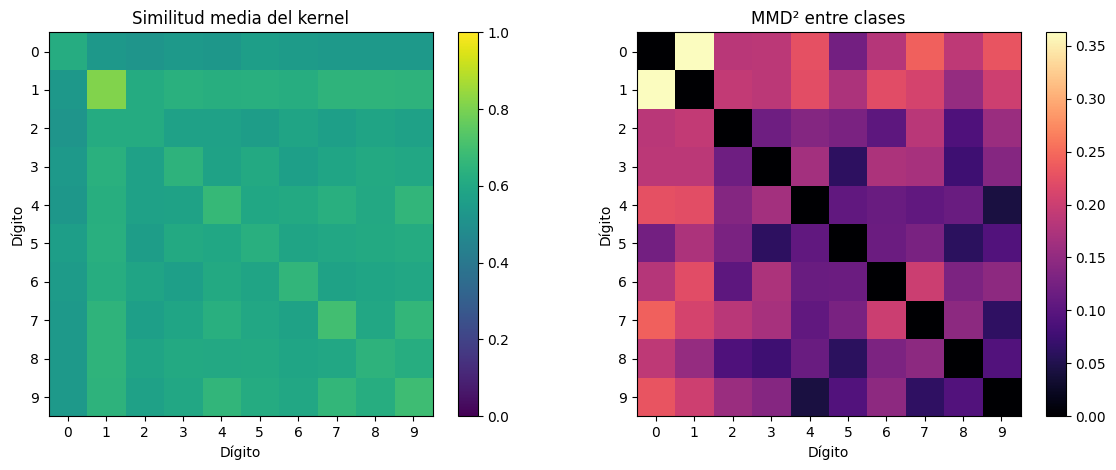

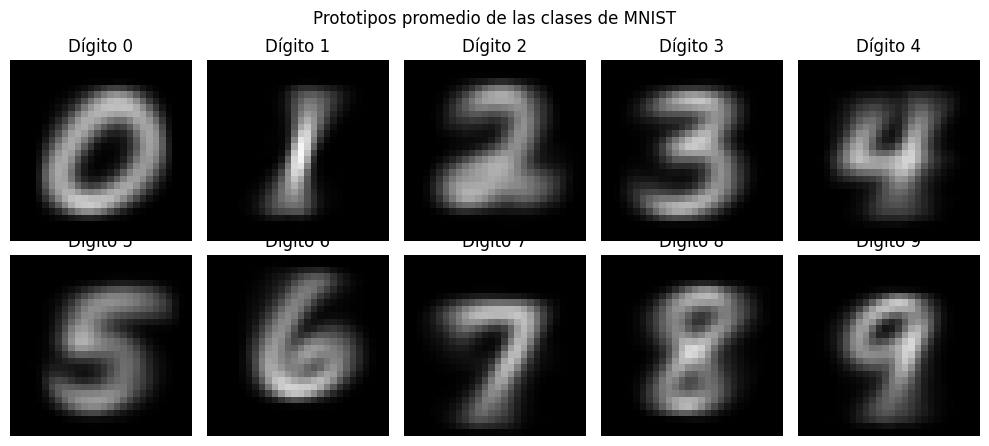

Tres pares más parecidos (menor MMD^2):
  dígitos 4-9: MMD^2 = 0.043822
  dígitos 5-8: MMD^2 = 0.060697
  dígitos 3-5: MMD^2 = 0.061548
Tres pares más separados (mayor MMD^2):
  dígitos 0-1: MMD^2 = 0.362640
  dígitos 0-7: MMD^2 = 0.241854
  dígitos 0-9: MMD^2 = 0.230112

MMD^2 de referencia entre dos mitades de MNIST: 0.001409
La comparación con la referencia ayuda a dimensionar la separación entre clases; ambas cantidades dependen del kernel y de sigma.


In [ ]:
# ============================================================
# 2.4.9 COMPARACIÓN DE LAS CLASES 0-9 DE MNIST
# ============================================================
# Las etiquetas se usan solamente para agrupar por dígito en esta subsección.
PCL = 500
N_CLASES = 10
etiquetas_mnist = np.asarray(mnist_ds.targets)
rng_clases = np.random.default_rng(SEED_MMD + 2)

# X_clases[d] almacena PCL imágenes de la clase d, cada una de 784 píxeles.
X_clases = np.zeros((N_CLASES, PCL, 784), dtype=np.float64)
for digito in range(N_CLASES):
    indices_clase = np.flatnonzero(etiquetas_mnist == digito)
    elegidos = rng_clases.choice(indices_clase, size=PCL, replace=False)
    X_clases[digito] = np.stack([
        mnist_ds[int(idx)][0].numpy().reshape(-1) for idx in elegidos
    ])

# Calcular y guardar una sola vez las Gram de cada clase consigo misma.
K_auto = [
    kernel_gaussiano(X_clases[d], X_clases[d], sigma)
    for d in range(N_CLASES)
]

# S[i,j]: similitud media entre las clases i y j.
# MMD2_clases[i,j]: MMD^2 sesgada entre las clases i y j.
S = np.zeros((N_CLASES, N_CLASES), dtype=np.float64)
MMD2_clases = np.zeros((N_CLASES, N_CLASES), dtype=np.float64)
for d in range(N_CLASES):
    S[d, d] = K_auto[d].mean()  # similitud media dentro de cada clase

for i in range(N_CLASES):
    for j in range(i + 1, N_CLASES):
        Kij = kernel_gaussiano(X_clases[i], X_clases[j], sigma)
        S[i, j] = S[j, i] = Kij.mean()
        valor_mmd = mmd2_sesgado(K_auto[i], K_auto[j], Kij)
        MMD2_clases[i, j] = MMD2_clases[j, i] = valor_mmd

# Resumen numérico de similitudes y distancias entre clases.
mascara_fuera_diagonal = ~np.eye(N_CLASES, dtype=bool)
print(f"Datos por clase: {PCL} | total usado: {N_CLASES * PCL} imágenes")
print(f"Sigma común: {sigma:.6f}")
print(f"Similitud media fuera de diagonal: {S[mascara_fuera_diagonal].mean():.6f}")
print(f"MMD^2 mínima entre clases distintas: {MMD2_clases[mascara_fuera_diagonal].min():.6f}")
print(f"MMD^2 máxima entre clases distintas: {MMD2_clases[mascara_fuera_diagonal].max():.6f}")

# Visualización de las matrices 10x10.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
im0 = axes[0].imshow(S, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title("Similitud media del kernel")
axes[0].set_xlabel("Dígito")
axes[0].set_ylabel("Dígito")
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(10))
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(MMD2_clases, cmap="magma")
axes[1].set_title("MMD² entre clases")
axes[1].set_xlabel("Dígito")
axes[1].set_ylabel("Dígito")
axes[1].set_xticks(range(10))
axes[1].set_yticks(range(10))
fig.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

# Prototipo visual: promedio de 500 imágenes de cada dígito.
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digito, ax in enumerate(axes.ravel()):
    promedio = X_clases[digito].mean(axis=0).reshape(28, 28)
    ax.imshow(promedio, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Dígito {digito}")
    ax.axis("off")
fig.suptitle("Prototipos promedio de las clases de MNIST")
plt.tight_layout()
plt.show()

# Mostrar los tres pares más parecidos y los tres más separados.
pares_clases = sorted(
    (MMD2_clases[i, j], i, j)
    for i in range(N_CLASES)
    for j in range(i + 1, N_CLASES)
)
print("Tres pares más parecidos (menor MMD^2):")
for valor, i, j in pares_clases[:3]:
    print(f"  dígitos {i}-{j}: MMD^2 = {valor:.6f}")
print("Tres pares más separados (mayor MMD^2):")
for valor, i, j in pares_clases[-3:][::-1]:
    print(f"  dígitos {i}-{j}: MMD^2 = {valor:.6f}")

print(f"\nMMD^2 de referencia entre dos mitades de MNIST: {mmd_referencia:.6f}")
print("La comparación con la referencia ayuda a dimensionar la separación entre clases; ambas cantidades dependen del kernel y de sigma.")

### Análisis de la sección 2.4

1. **Referencia muestral:** `mnist_A` y `mnist_B` son dos muestras disjuntas del mismo conjunto MNIST. El estimador sesgado puede ser positivo incluso cuando las muestras proceden de la misma distribución.
2. **Ancho de banda:** los resultados dependen de $\sigma$. Las comparaciones de esta sección usan el mismo valor base de $\sigma$, salvo en el análisis de sensibilidad donde se cambia deliberadamente.
3. **Comparación entre clases:** la MMD² y la similitud media resumen las diferencias de las distribuciones empíricas de los dígitos bajo el kernel gaussiano. La MMD² es una medida de discrepancia, no un valor $p$ ni por sí sola una prueba de hipótesis.
4. **Alcance:** todas las comparaciones realizadas aquí están dentro de MNIST: entre dos submuestras y entre dígitos. No se realiza comparación con otro conjunto de imágenes.

# Pregunta 3: Índice de correlación de Pearson — espacio original y RKHS

## 3.1 Coeficiente de Pearson en el espacio original

> **Enunciado.** Sean $X$, $Y$ variables aleatorias escalares con varianzas positivas y $x,y\in\mathbb{R}^{N\times1}$ los vectores de $N$ observaciones emparejadas. A partir de
> $$\rho_{XY}=\frac{\mathbb{E}[(X-\mu_X)(Y-\mu_Y)]}{\sqrt{\mathbb{E}[(X-\mu_X)^2]\,\mathbb{E}[(Y-\mu_Y)^2]}},$$
> demuestre que el coeficiente muestral puede expresarse como $\hat\rho_{XY}=\dfrac{x^\top Hy}{\sqrt{(x^\top Hx)(y^\top Hy)}}$ con $H=I_N-\frac1N\mathbf{1}_N\mathbf{1}_N^\top$.

#### Paso 1: de las esperanzas a promedios muestrales

Con observaciones i.i.d. (como en clase: $\mathbb{E}\{X\}\overset{i.i.d.}{=}\frac1N\sum_nX_n$) se reemplazan las esperanzas por promedios:

$$\hat\mu_X=\bar x=\frac1N\sum_{i=1}^Nx_i=\frac1N\mathbf{1}_N^\top x,\qquad\hat\mu_Y=\bar y=\frac1N\mathbf{1}_N^\top y,$$

$$\widehat{\mathrm{Cov}}(X,Y)=\frac1N\sum_{i=1}^N(x_i-\bar x)(y_i-\bar y),\quad\widehat{\mathrm{Var}}(X)=\frac1N\sum_i(x_i-\bar x)^2,\quad\widehat{\mathrm{Var}}(Y)=\frac1N\sum_i(y_i-\bar y)^2 .$$

#### Paso 2: el centrado en forma matricial

El vector de $N$ componentes iguales a $\bar x$ es $\bar x\mathbf{1}_N=\mathbf{1}_N\frac1N\mathbf{1}_N^\top x=\frac1N\mathbf{1}_N\mathbf{1}_N^\top x$ (producto externo $\mathbf{1}_N\mathbf{1}_N^\top\in\mathbb{R}^{N\times N}$, la matriz de todos unos). Entonces el vector centrado es

$$x_c=x-\bar x\mathbf{1}_N=\Big(I_N-\frac1N\mathbf{1}_N\mathbf{1}_N^\top\Big)x=Hx,\qquad y_c=Hy .$$

**Propiedades de $H\in\mathbb{R}^{N\times N}$:**

- *Simétrica:* $H^\top=I_N-\frac1N(\mathbf{1}_N\mathbf{1}_N^\top)^\top=H$.
- *Idempotente:* usando $\mathbf{1}_N^\top\mathbf{1}_N=N$,
$$H^2=I_N-\frac2N\mathbf{1}_N\mathbf{1}_N^\top+\frac1{N^2}\mathbf{1}_N(\mathbf{1}_N^\top\mathbf{1}_N)\mathbf{1}_N^\top=I_N-\frac2N\mathbf{1}_N\mathbf{1}_N^\top+\frac1N\mathbf{1}_N\mathbf{1}_N^\top=H .$$
- *Anula las constantes:* $H\mathbf{1}_N=\mathbf{1}_N-\frac1N\mathbf{1}_N N=0$ (por eso centra: $\mathbf{1}_N^\top Hx=0$). $H$ es la proyección ortogonal sobre $\mathbf{1}_N^\perp$ (rango $N-1$).

#### Paso 3: sumatorias a productos internos

Una suma de productos es un producto interno de vectores columna: $\sum_i(x_i-\bar x)(y_i-\bar y)=x_c^\top y_c$ (dimensión $(1\times N)(N\times1)=1\times1$). Usando simetría e idempotencia de $H$:

$$x_c^\top y_c=(Hx)^\top(Hy)=x^\top H^\top Hy=x^\top H^2y=x^\top Hy,\qquad\sum_i(x_i-\bar x)^2=x^\top Hx,\qquad\sum_i(y_i-\bar y)^2=y^\top Hy .$$

#### Paso 4: cociente

$$\hat\rho_{XY}=\frac{\frac1Nx^\top Hy}{\sqrt{\frac1Nx^\top Hx\cdot\frac1Ny^\top Hy}}=\boxed{\frac{x^\top Hy}{\sqrt{(x^\top Hx)(y^\top Hy)}}}\ \blacksquare$$

El factor $1/N$ se cancela entre numerador y denominador, por lo que el resultado es el mismo con la convención $1/N$ o $1/(N-1)$. Las varianzas positivas garantizan denominador no nulo ($x^\top Hx=\|Hx\|^2>0$ si $x$ no es constante).

**Lectura geométrica (conexión con clase).** $\hat\rho_{XY}=\dfrac{\langle x_c,y_c\rangle}{\|x_c\|_2\|y_c\|_2}=\cos\theta_{x_cy_c}$: el coeficiente de Pearson es el **coseno del ángulo entre los vectores centrados** (la misma fórmula $\cos\theta=\langle x,y\rangle/(\|x\|\|y\|)$ del espacio de Hilbert $L_2$), y por Cauchy–Schwarz $|\hat\rho_{XY}|\le1$.

**Dimensiones:** $x,y\in\mathbb{R}^{N\times1}$; $H\in\mathbb{R}^{N\times N}$; $Hy\in\mathbb{R}^{N\times1}$; $x^\top Hy\in\mathbb{R}^{1\times1}$.

## 3.2 Correlación matricial en RKHS (alineamiento centrado de kernels)

> **Enunciado.** Sean $X\in\mathbb{R}^P$ y $Y\in\mathbb{R}^Q$ con $N$ observaciones emparejadas y kernels $k_X,k_Y$ con matrices de Gram $K_X,K_Y\in\mathbb{R}^{N\times N}$. Partiendo del producto interno normalizado entre las matrices de Gram centradas, demuestre
> $$\rho_{RKHS}(K_X,K_Y)=\frac{\mathrm{tr}(K_XHK_YH)}{\sqrt{\mathrm{tr}(K_XHK_XH)\,\mathrm{tr}(K_YHK_YH)}} .$$
> Con $K_{X,c}=HK_XH$, $K_{Y,c}=HK_YH$. Finalmente, para kernels lineales y $P=Q=1$, demuestre $\rho_{RKHS}=\hat\rho_{XY}^2$ y explique la pérdida del signo.

#### Qué significa "centrar" una Gram

Sea $\Phi_X\in\mathbb{R}^{N\times Q_X}$ la matriz de características ($K_X=\Phi_X\Phi_X^\top$). Centrar las características en el RKHS es $\Phi_{X,c}=H\Phi_X$ (resta la media $\hat\mu_{\phi}$ a cada $\phi(x_i)$). Su Gram es

$$\Phi_{X,c}\Phi_{X,c}^\top=H\Phi_X\Phi_X^\top H^\top=HK_XH=K_{X,c}\in\mathbb{R}^{N\times N},$$

o, entrada a entrada, $(K_{X,c})_{ij}=\langle\phi(x_i)-\bar\phi,\phi(x_j)-\bar\phi\rangle=K_{ij}-\frac1N\sum_lK_{il}-\frac1N\sum_lK_{lj}+\frac1{N^2}\sum_{l,l'}K_{ll'}$. (Es el análogo matricial del cálculo de covarianza en el RKHS hecho en clase.) $K_{X,c}$ es simétrica ($H$ y $K_X$ lo son) y semidefinida positiva.

#### Paso 1: producto interno de Frobenius entre Gram centradas

En el espacio de matrices $\mathbb{R}^{N\times N}$ el producto interno es $\langle A,B\rangle_F=\sum_{i,j}A_{ij}B_{ij}=\mathrm{tr}(A^\top B)$, con norma $\|A\|_F=\sqrt{\langle A,A\rangle_F}$. El alineamiento es el producto interno **normalizado** (coseno del ángulo entre las dos Gram centradas):

$$\rho_{RKHS}=\frac{\langle K_{X,c},K_{Y,c}\rangle_F}{\|K_{X,c}\|_F\,\|K_{Y,c}\|_F}=\frac{\sum_{ij}(K_{X,c})_{ij}(K_{Y,c})_{ij}}{\sqrt{\sum_{ij}(K_{X,c})_{ij}^2}\sqrt{\sum_{ij}(K_{Y,c})_{ij}^2}} .$$

#### Paso 2: de sumatorias a trazas

$$\langle K_{X,c},K_{Y,c}\rangle_F=\mathrm{tr}(K_{X,c}^\top K_{Y,c})=\mathrm{tr}\big((HK_XH)^\top HK_YH\big)=\mathrm{tr}(HK_XH\,HK_YH),$$

donde se usó $(HK_XH)^\top=H^\top K_X^\top H^\top=HK_XH$. Como $HH=H$ (idempotencia, 3.1),

$$\mathrm{tr}(HK_XH\,HK_YH)=\mathrm{tr}(HK_XHK_YH)\overset{\text{cíclica}}{=}\mathrm{tr}(K_XHK_YH\,H)=\mathrm{tr}(K_XHK_YH),$$

pues $\mathrm{tr}(AB)=\mathrm{tr}(BA)$ permite mover el $H$ inicial al final, y luego $HH=H$. **Dimensiones:** todos los factores son $N\times N$, el producto es $N\times N$ y la traza es un escalar.

De la misma forma, los denominadores son

$$\|K_{X,c}\|_F^2=\mathrm{tr}(K_{X,c}^\top K_{X,c})=\mathrm{tr}(K_XHK_XH),\qquad\|K_{Y,c}\|_F^2=\mathrm{tr}(K_YHK_YH).$$

#### Paso 3: resultado

$$\boxed{\rho_{RKHS}(K_X,K_Y)=\frac{\mathrm{tr}(K_XHK_YH)}{\sqrt{\mathrm{tr}(K_XHK_XH)\,\mathrm{tr}(K_YHK_YH)}}}\ \blacksquare$$

(Se supone $K_{X,c}\ne0$ y $K_{Y,c}\ne0$.) Por Cauchy–Schwarz $\rho_{RKHS}\le1$, y como $K_{X,c},K_{Y,c}\succeq0$ se tiene $\mathrm{tr}(K_{X,c}K_{Y,c})\ge0$, luego $\rho_{RKHS}\in[0,1]$: **no es el coeficiente de Pearson** sino el alineamiento centrado de kernels. Además, $\mathrm{tr}(HK_XH)/N$ es la traza de la covarianza en el RKHS, que coincide con $\frac1N\sum_nk(x_n,x_n)-\frac1{N^2}\sum_{n,n'}k(x_n,x_{n'})$ obtenido en clase.

#### Caso lineal con $P=Q=1$: $\rho_{RKHS}=\hat\rho_{XY}^2$

Con kernels lineales $k(u,v)=uv$ y observaciones escalares: $K_X=xx^\top$, $K_Y=yy^\top$ (ambas $N\times N$ de rango 1). Usando que $\mathrm{tr}(ab^\top)=b^\top a$ y que $x^\top Hy$ es escalar:

$$\mathrm{tr}(K_XHK_YH)=\mathrm{tr}(xx^\top H\,yy^\top H)=\mathrm{tr}\big(x\,[x^\top Hy]\,y^\top H\big)=(x^\top Hy)\,\mathrm{tr}(xy^\top H)=(x^\top Hy)(y^\top Hx)=(x^\top Hy)^2,$$

(con $y^\top Hx=x^\top H^\top y=x^\top Hy$). Análogamente $\mathrm{tr}(K_XHK_XH)=(x^\top Hx)^2$ y $\mathrm{tr}(K_YHK_YH)=(y^\top Hy)^2$. Entonces, como $x^\top Hx=\|Hx\|^2\ge0$ y $y^\top Hy\ge0$,

$$\rho_{RKHS}=\frac{(x^\top Hy)^2}{\sqrt{(x^\top Hx)^2(y^\top Hy)^2}}=\frac{(x^\top Hy)^2}{(x^\top Hx)(y^\top Hy)}=\Big(\frac{x^\top Hy}{\sqrt{(x^\top Hx)(y^\top Hy)}}\Big)^2=\hat\rho_{XY}^2\ \blacksquare$$

**Pérdida del signo.** El kernel lineal depende de los datos solo a través de $xx^\top$ y $yy^\top$, que son **invariantes** a $x\mapsto-x$ (o $y\mapsto-y$), operación que cambia el signo de $\hat\rho_{XY}$. La covarianza aparece en el numerador de forma cuadrática, $(x^\top Hy)^2$, así que $\hat\rho_{XY}=+0.9$ y $\hat\rho_{XY}=-0.9$ producen el mismo $\rho_{RKHS}=0.81$. El alineamiento mide *cuánta* dependencia hay (en $[0,1]$), no su **dirección** (positiva o negativa). En general, con kernels lineales $\mathrm{tr}(K_XHK_YH)=\|X_c^\top Y_c\|_F^2$, el cuadrado de la covarianza cruzada entre las variables centradas.

#### Verificación numérica (Pregunta 3)

In [ ]:
rng3 = np.random.default_rng(0)
N3 = 200
H = np.eye(N3) - np.ones((N3, N3)) / N3

# ---------- 3.1: Pearson matricial vs np.corrcoef ----------
x = rng3.standard_normal(N3)
y = -0.8 * x + 0.3 * rng3.standard_normal(N3)       # correlacion negativa
rho_H = (x @ H @ y) / np.sqrt((x @ H @ x) * (y @ H @ y))
print(f"3.1  rho (matricial con H) = {rho_H:.6f} | np.corrcoef = {np.corrcoef(x, y)[0,1]:.6f}")
print("     H simetrica:", np.allclose(H, H.T), "| H idempotente:", np.allclose(H @ H, H), "| H 1 = 0:", np.allclose(H @ np.ones(N3), 0))

# ---------- 3.2: alineamiento centrado ----------
def alineamiento(KX, KY):
    N = KX.shape[0]; H = np.eye(N) - np.ones((N, N)) / N
    num = np.trace(KX @ H @ KY @ H)
    den = np.sqrt(np.trace(KX @ H @ KX @ H) * np.trace(KY @ H @ KY @ H))
    return num / den

def alineamiento_frobenius(KX, KY):                  # definicion directa con las Gram centradas
    N = KX.shape[0]; H = np.eye(N) - np.ones((N, N)) / N
    A, B = H @ KX @ H, H @ KY @ H
    return np.sum(A * B) / (np.linalg.norm(A, "fro") * np.linalg.norm(B, "fro"))

K_lin_x, K_lin_y = np.outer(x, x), np.outer(y, y)    # kernels lineales, P = Q = 1
print(f"\n3.2  rho_RKHS (traza)      = {alineamiento(K_lin_x, K_lin_y):.6f}")
print(f"     rho_RKHS (Frobenius)  = {alineamiento_frobenius(K_lin_x, K_lin_y):.6f}   (misma cantidad)")
print(f"     rho_hat^2             = {rho_H**2:.6f}   (kernel lineal, P=Q=1: rho_RKHS = rho_hat^2)")

# perdida de signo: -y da el mismo alineamiento pero rho_hat cambia de signo
y_neg = -y
rho_neg = (x @ H @ y_neg) / np.sqrt((x @ H @ x) * (y_neg @ H @ y_neg))
print(f"\nPerdida del signo: rho_hat(x,y) = {rho_H:+.4f}, rho_hat(x,-y) = {rho_neg:+.4f}  |  "
      f"rho_RKHS(x,y) = {alineamiento(K_lin_x, K_lin_y):.4f}, rho_RKHS(x,-y) = {alineamiento(K_lin_x, np.outer(y_neg, y_neg)):.4f}")

# Complemento: dependencia no lineal (y = x^2). Pearson ~ 0, el kernel RBF si la detecta.
def rbf_gram_1d(v):
    d2 = (v[:, None] - v[None, :]) ** 2
    s = np.sqrt(np.median(d2[np.triu_indices(len(v), 1)]))     # mediana de distancias
    return np.exp(-d2 / (2 * s ** 2))

z = rng3.uniform(-1, 1, N3); w2 = z ** 2 + 0.02 * rng3.standard_normal(N3)   # relacion simetrica: covarianza lineal ~ 0
rho_z = (z @ H @ w2) / np.sqrt((z @ H @ z) * (w2 @ H @ w2))
print(f"\nDependencia no lineal w = z^2:  Pearson = {rho_z:+.3f} | rho_RKHS lineal = {alineamiento(np.outer(z,z), np.outer(w2,w2)):.3f}"
      f" | rho_RKHS (RBF) = {alineamiento(rbf_gram_1d(z), rbf_gram_1d(w2)):.3f}")

3.1  rho (matricial con H) = -0.931949 | np.corrcoef = -0.931949
     H simetrica: True | H idempotente: True | H 1 = 0: True

3.2  rho_RKHS (traza)      = 0.868529
     rho_RKHS (Frobenius)  = 0.868529   (misma cantidad)
     rho_hat^2             = 0.868529   (kernel lineal, P=Q=1: rho_RKHS = rho_hat^2)

Perdida del signo: rho_hat(x,y) = -0.9319, rho_hat(x,-y) = +0.9319  |  rho_RKHS(x,y) = 0.8685, rho_RKHS(x,-y) = 0.8685

Dependencia no lineal w = z^2:  Pearson = +0.046 | rho_RKHS lineal = 0.002 | rho_RKHS (RBF) = 0.359


**Lectura de la verificación.** (i) La forma matricial con $H$ reproduce exactamente `np.corrcoef`; (ii) con kernel lineal y $P=Q=1$, la traza y la definición de Frobenius coinciden y valen $\hat\rho^2_{XY}$; (iii) cambiar $y\to-y$ invierte el signo de $\hat\rho_{XY}$ pero deja intacto $\rho_{RKHS}$, ilustrando la pérdida del signo; (iv) en el ejemplo $w=z^2$ el Pearson es casi 0 (no hay relación *lineal*) y el kernel lineal tampoco la ve ($\rho_{RKHS}=\hat\rho^2\approx0$), mientras que el kernel RBF sí detecta la dependencia: ese es el valor añadido de pasar del espacio original al RKHS.

---
# Resumen final del cuaderno

| Sección | Qué debes poder explicar |
|---|---|
| **1.1–1.4** | Derivación de LS, Ridge, ML y MAP; condiciones de existencia/unicidad; relación entre penalización y prior gaussiano. |
| **1.5** | Construcción de $\Phi(X)$, partición train/test, métricas, igualdad numérica LS = ML y Ridge = MAP, y comparación repetida entre LS y Ridge. |
| **2.1–2.3** | Embedding de media en el RKHS, propiedad reproductora y forma matricial del estimador sesgado de MMD². |
| **2.4** | Kernel gaussiano para imágenes MNIST, elección de $\sigma$, referencia entre dos mitades y comparación entre las clases 0–9. |
| **3.1–3.2** | Matriz de centrado $H$, Pearson matricial, alineamiento centrado de kernels y pérdida del signo para el kernel lineal. |

**Antes de ejecutar todo:** en Google Colab, selecciona **Entorno de ejecución → Ejecutar todo**. La descarga de MNIST de la sección 2.4 requiere conexión a internet la primera vez. Las demás secciones generan sus propios datos.